In [5]:
# ──  Dependencies ──────────────────────────────────────────────────────────
import subprocess, sys
def _install(pkg):
    subprocess.check_call([sys.executable,'-m','pip','install','-q',pkg])
for pkg in ['rdkit','xgboost','imbalanced-learn','scikit-learn',
            'matplotlib','seaborn','openpyxl','torch','torch-geometric']:
    try: __import__(pkg.replace('-','_'))
    except ImportError: _install(pkg)
print('Dependencies OK.')

Dependencies OK.


In [6]:
# ── Imports ────────────────────────────────────────────────────────────────
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import copy, time

from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import (
    roc_auc_score, average_precision_score, matthews_corrcoef,
    balanced_accuracy_score, f1_score, confusion_matrix,
    roc_curve, precision_recall_curve, classification_report
)
from xgboost import XGBClassifier

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import GCNConv, GATConv, GINConv, SAGEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cpu


---
## Step 1 — Data Loading, Curation & Label Assignment


In [7]:
# ──  Load ────────────────────────────────────────────────────────────────
df_raw = pd.read_excel('AID_720635_cleaned.xlsx',
    usecols=['PUBCHEM_CID','PUBCHEM_EXT_DATASOURCE_SMILES',
             'PUBCHEM_ACTIVITY_SCORE','PUBCHEM_ACTIVITY_OUTCOME'])
print(f'Raw rows : {len(df_raw):,}')
print(df_raw['PUBCHEM_ACTIVITY_OUTCOME'].value_counts())
print(df_raw['PUBCHEM_ACTIVITY_SCORE'].describe())


Raw rows : 8,099
PUBCHEM_ACTIVITY_OUTCOME
Inconclusive    3474
Inactive        3213
Active          1412
Name: count, dtype: int64
count    8099.000000
mean       15.672429
std        23.805444
min         0.000000
25%         0.000000
50%        10.000000
75%        10.000000
max        99.000000
Name: PUBCHEM_ACTIVITY_SCORE, dtype: float64


In [8]:
# ──   SMILES + deduplication ──────────────────────────
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi)) #converts to mol object, returns None if invalid
        return Chem.MolToSmiles(mol) if mol else None
    except: return None

df_raw['csmi'] = df_raw['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df = df_raw.dropna(subset=['csmi'])
print(f'After parse : {len(df):,}  (removed {len(df_raw)-len(df)} invalid SMILES)')
df = df.drop_duplicates('csmi', keep='first').reset_index(drop=True)
print(f'After dedup : {len(df):,}')


[12:45:49] WARNING: not removing hydrogen atom without neighbors


After parse : 8,099  (removed 0 invalid SMILES)
After dedup : 8,099


[12:45:49] WARNING: not removing hydrogen atom without neighbors
[12:45:49] WARNING: not removing hydrogen atom without neighbors


Removed 3,474 inconclusive
Active   (1): 1,412
Inactive (0): 3,213
Ratio       : 2.3:1


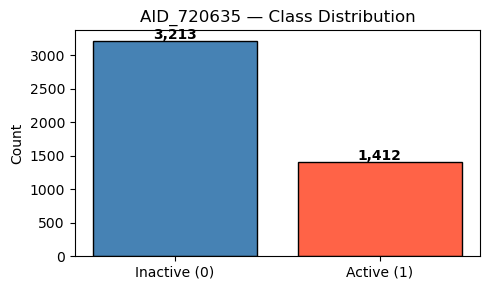

In [ ]:
# ── Binary Labels
#  Active (score >= 40) -> 1 | Inactive (score = 0) -> 0 | Inconclusive -> drop
df['label'] = df['PUBCHEM_ACTIVITY_SCORE'].apply(
    lambda s: 1 if s>=40 else (0 if s==0 else np.nan))
n_inc = df['label'].isna().sum()
df = df.dropna(subset=['label']).copy()
df['label'] = df['label'].astype(int)

n_act, n_ina = (df['label']==1).sum(), (df['label']==0).sum()
print(f'Removed {n_inc:,} inconclusive')
print(f'Active   (1): {n_act:,}')
print(f'Inactive (0): {n_ina:,}')
print(f'Ratio       : {n_ina/n_act:.1f}:1')

fig, ax = plt.subplots(figsize=(5,3))
bars = ax.bar(['Inactive (0)','Active (1)'],[n_ina,n_act],
              color=['steelblue','tomato'], edgecolor='black')
for b,v in zip(bars,[n_ina,n_act]):
    ax.text(b.get_x()+b.get_width()/2, v+30, f'{v:,}', ha='center', fontweight='bold')
ax.set_title('AID_720635 — Class Distribution')
ax.set_ylabel('Count')
plt.tight_layout(); plt.savefig('class_dist.png',dpi=150); plt.show()


---
## Step 2 — Feature Engineering

### 2A. Morgan Fingerprints (ECFP4) — for Classical ML
### 2B. Rich Atom/Bond Graph Features — for GNN


In [10]:
# ── 5. Morgan ECFP4 (2048 bits) ─────────────────────────────────────────────
def smiles_to_ecfp4(smi, radius=2, n_bits=2048):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    fp  = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr

fps = df['csmi'].apply(smiles_to_ecfp4)
valid = fps.notna()
df    = df[valid].reset_index(drop=True)
fps   = fps[valid]
X_fp  = np.vstack(fps.values)   # (N, 2048)
y_all = df['label'].values
print(f'Fingerprint matrix : {X_fp.shape}')
print(f'FP density         : {X_fp.mean():.4f}')


[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerator
[12:45:49] DEPRECATION WARNING: please use MorganGenerat

Fingerprint matrix : (4625, 2048)
FP density         : 0.0146


[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerator
[12:45:50] DEPRECATION WARNING: please use MorganGenerat

In [11]:
# ──  Rich Atom Features (14-dim) & Bond Features (6-dim) — for GNN ─────────
#
#  14 atom features 
#    Atomic num one-hot (C,N,O,S,F,P,Cl,Br,I,other=10),
#    degree (0-5), formal charge, hybridization one-hot (SP/SP2/SP3/other=4),
#    is_aromatic, is_in_ring, total_Hs (0-4), normalized mass
#
#  6 bond features:
#    bond type one-hot (single/double/triple/aromatic=4),
#    is_conjugated, is_in_ring
#
ATOM_SYMBOLS = [6,7,8,16,9,15,17,35,53]  # C N O S F P Cl Br I

def one_hot(val, choices):
    vec = [0]*len(choices)
    try: vec[choices.index(val)] = 1
    except ValueError: pass   # 'other' → all zeros
    return vec

from rdkit.Chem import rdchem
HYBRID_MAP = {
    rdchem.HybridizationType.SP  : 0,
    rdchem.HybridizationType.SP2 : 1,
    rdchem.HybridizationType.SP3 : 2,
}

def atom_feat(atom):
    at_oh  = one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [0]  # 10-dim (+other)
    hyb    = [0,0,0,0]
    hyb[HYBRID_MAP.get(atom.GetHybridization(), 3)] = 1
    deg    = min(atom.GetDegree(), 5) #no of bonds this atom has
    deg_oh = [0]*6; deg_oh[deg]=1
    fc     = atom.GetFormalCharge() #chareg positve or nehative or zero
    fc_enc = [1 if fc<0 else 0, 1 if fc==0 else 0, 1 if fc>0 else 0]
    extras = [
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        min(atom.GetTotalNumHs(), 4) / 4.0,
        atom.GetMass() / 100.0
    ]
    return at_oh + deg_oh + fc_enc + hyb + extras  # 10+6+3+4+4 = 27-dim

BOND_TYPES = [
    rdchem.BondType.SINGLE,
    rdchem.BondType.DOUBLE,
    rdchem.BondType.TRIPLE,
    rdchem.BondType.AROMATIC
]

def bond_feat(bond):
    bt = one_hot(bond.GetBondType(), BOND_TYPES)  # 4-dim
    return bt + [int(bond.GetIsConjugated()), int(bond.IsInRing())]  # 6-dim

# Test dimensions
from rdkit.Chem import MolFromSmiles
_mol = MolFromSmiles('CC(=O)O')
ATOM_DIM = len(atom_feat(_mol.GetAtomWithIdx(0)))
BOND_DIM  = len(bond_feat(_mol.GetBondWithIdx(0)))
print(f'Atom feature dim : {ATOM_DIM}')
print(f'Bond feature dim : {BOND_DIM}')


Atom feature dim : 27
Bond feature dim : 6


In [12]:
# ── 7. Build Graph Dataset ───────────────────────────────────────────────────
def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    # Atom features
    x = torch.tensor([atom_feat(a) for a in mol.GetAtoms()], dtype=torch.float)
    # Bond features + bidirectional edges
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_feat(bond)
        ei += [[i,j],[j,i]]
        ea += [bf, bf]
    if ei:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    else:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    y = torch.tensor([label], dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr, y=y)

graph_list = []
for smi, lbl in zip(df['csmi'].values, y_all):
    g = mol_to_graph(smi, lbl)
    if g: graph_list.append(g)

print(f'Graphs built: {len(graph_list):,}')
print(f'Example: {graph_list[0]}')


[12:45:50] WARNING: not removing hydrogen atom without neighbors


Graphs built: 4,625
Example: Data(x=[13, 27], edge_index=[2, 26], edge_attr=[26, 6], y=[1])


[12:45:51] WARNING: not removing hydrogen atom without neighbors
[12:45:51] WARNING: not removing hydrogen atom without neighbors


---
## Step 3 — 80/20/20 Split + Downsampling


In [13]:
# ── 8. 20% External Test Split ───────────────────────────────────────────────
X_pool, X_test, y_pool, y_test = train_test_split(
    X_fp, y_all, test_size=0.20, stratify=y_all, random_state=SEED)

# Parallel split for graph data (using same indices)
idx_all   = np.arange(len(y_all))
idx_pool, idx_test = train_test_split(
    idx_all, test_size=0.20, stratify=y_all, random_state=SEED)

graphs_pool = [graph_list[i] for i in idx_pool]
graphs_test = [graph_list[i] for i in idx_test]

print(f'Pool : {len(y_pool):,}  (act={( y_pool==1).sum()}, ina={(y_pool==0).sum()})')
print(f'Test : {len(y_test):,}  (act={(y_test==1).sum()}, ina={(y_test==0).sum()})')


Pool : 3,700  (act=1130, ina=2570)
Test : 925  (act=282, ina=643)


In [14]:
# ── Print Test Set Values ─────────────────────────────────────────────────────
df_test = df.iloc[idx_test].reset_index(drop=True).copy()
df_test['label'] = y_test

print(f'Test set size : {len(df_test):,} compounds')
print(f'X_test shape  : {X_test.shape}   (compounds × ECFP4 bits)')
print(f'y_test shape  : {y_test.shape}')
print(f'\nClass distribution:')
print(f'  Active   (1): {(y_test == 1).sum():,}')
print(f'  Inactive (0): {(y_test == 0).sum():,}')

print(f'\n── First 10 test set compounds ──')
display(df_test[['PUBCHEM_CID', 'csmi', 'PUBCHEM_ACTIVITY_SCORE', 'label']].head(20))

print(f'\n── Fingerprint values (X_test) — first 5 rows, first 20 bits ──')
print(X_test[:5, :20])

print(f'\n── Labels (y_test) — first 20 values ──')
print(y_test[:20])


Test set size : 925 compounds
X_test shape  : (925, 2048)   (compounds × ECFP4 bits)
y_test shape  : (925,)

Class distribution:
  Active   (1): 282
  Inactive (0): 643

── First 10 test set compounds ──


,PUBCHEM_CID,csmi,PUBCHEM_ACTIVITY_SCORE,label
0,16036578,O=C(NS(=O)(=O)/C=C/c1cccs1)c1ccc(F)cc1Br,41,1
1,13849,CCCCCCCCCCCCCCC(=O)O,0,0
2,2734247,CCCCCCn1cc[n+](C)c1.O=S(=O)([O-])C(F)(F)F,42,1
3,38764,CCCCCCc1ccc(-c2ccc(C#N)cc2)cc1,40,1
4,91692,O=C(Nc1ccccc1)N(Cc1ccc(Cl)cc1)C1CCCC1,82,1
5,2197,COc1ccc(C2C(=O)c3ccccc3C2=O)cc1,0,0
6,92729,Cc1c(O)cc2c(c1C)O[C@](C)(CCC[C@H](C)CCC[C@H](C...,0,0
7,2735045,CCOC(=S)[S-].[K+],0,0
8,5281116,CCCCCCCC/C=C\CCCCCCCCCCCC(=O)O,0,0
9,12120,CCOc1cccc(N)c1,0,0



── Fingerprint values (X_test) — first 5 rows, first 20 bits ──
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

── Labels (y_test) — first 20 values ──
[1 0 1 1 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0]


In [15]:
# ── 80/20 Train/Val Split from Pool ────────────────────────────────────────
X_tr_raw, X_val, y_tr_raw, y_val = train_test_split(
    X_pool, y_pool, test_size=0.20, stratify=y_pool, random_state=SEED)

pool_sub_idx = np.arange(len(y_pool))
tr_sub_idx, val_sub_idx = train_test_split(
    pool_sub_idx, test_size=0.20, stratify=y_pool, random_state=SEED)

graphs_val  = [graphs_pool[i] for i in val_sub_idx]
graphs_trraw = [graphs_pool[i] for i in tr_sub_idx]

print(f'Train-raw: {len(y_tr_raw):,}  (act={(y_tr_raw==1).sum()}, ina={(y_tr_raw==0).sum()})')
print(f'Val      : {len(y_val):,}  (act={(y_val==1).sum()},  ina={(y_val==0).sum()})')


Train-raw: 2,960  (act=904, ina=2056)
Val      : 740  (act=226,  ina=514)


In [16]:
# ──  Downsampling on TRAIN ONLY ──────────────────────────────
act_idx_tr  = np.where(y_tr_raw == 1)[0]
ina_idx_tr  = np.where(y_tr_raw == 0)[0]
n_act_tr    = len(act_idx_tr)

rng = np.random.RandomState(SEED)
sampled_ina = rng.choice(ina_idx_tr, size=n_act_tr, replace=False)

train_idx   = np.concatenate([act_idx_tr, sampled_ina])
rng.shuffle(train_idx)

X_train = X_tr_raw[train_idx]
y_train = y_tr_raw[train_idx]
graphs_train = [graphs_trraw[i] for i in train_idx]

print(f'Balanced TRAIN: {len(y_train):,}  act={(y_train==1).sum()} / ina={(y_train==0).sum()} (1:1)')
print(f'VAL  (real-world imbalance): {len(y_val):,}  ratio={(y_val==0).sum()/(y_val==1).sum():.1f}:1')
print(f'TEST (real-world imbalance): {len(y_test):,}  ratio={(y_test==0).sum()/(y_test==1).sum():.1f}:1')


Balanced TRAIN: 1,808  act=904 / ina=904 (1:1)
VAL  (real-world imbalance): 740  ratio=2.3:1
TEST (real-world imbalance): 925  ratio=2.3:1


Split summary (% of total)
  Train: 1,808 (39.1%)  act=904, ina=904
  Val  :   740 (16.0%)  act=226, ina=514
  Test :   925 (20.0%)  act=282, ina=643


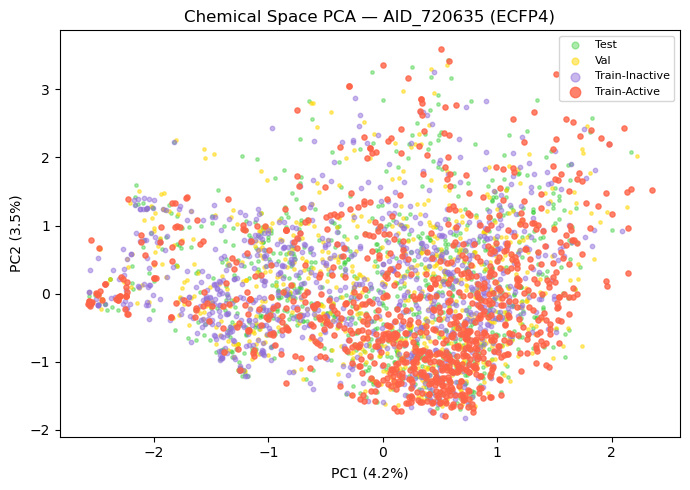

In [17]:
# ── 11. Split Summary & Chemical Space PCA ───────────────────────────────────
print('Split summary (% of total)')
for name, ys in [('Train',y_train),('Val',y_val),('Test',y_test)]:
    print(f'  {name:5s}: {len(ys):5,} ({100*len(ys)/len(y_all):.1f}%)  '
          f'act={( ys==1).sum()}, ina={(ys==0).sum()}')

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_train)
tr_p, va_p, te_p = pca.transform(X_train), pca.transform(X_val), pca.transform(X_test)

fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(te_p[:,0], te_p[:,1], c='limegreen', s=6, alpha=0.4, label='Test')
ax.scatter(va_p[:,0], va_p[:,1], c='gold',      s=6, alpha=0.5, label='Val')
ax.scatter(tr_p[y_train==0,0], tr_p[y_train==0,1], c='mediumpurple', s=10, alpha=0.5, label='Train-Inactive')
ax.scatter(tr_p[y_train==1,0], tr_p[y_train==1,1], c='tomato',       s=14, alpha=0.8, label='Train-Active')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title('Chemical Space PCA — AID_720635 (ECFP4)')
ax.legend(markerscale=2, fontsize=8); plt.tight_layout()
plt.savefig('chem_space.png',dpi=150); plt.show()


Left-out inactives : 1,152
PC1: 4.2%  PC2: 3.5%  PC3: 2.6%
Total variance explained: 10.3%


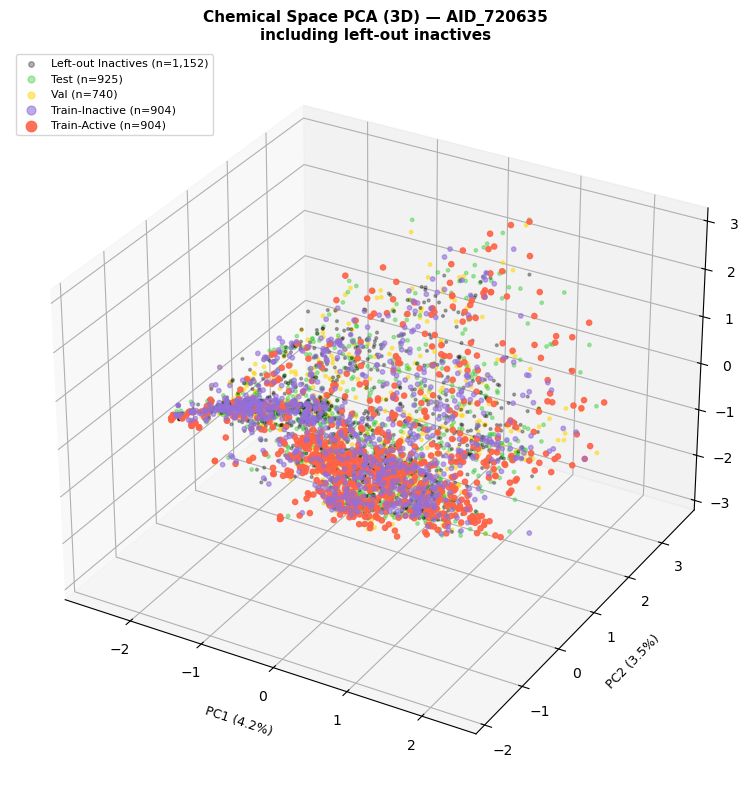

In [18]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA

# ── Find the left-out (discarded) inactives ──────────────────────────────────
sampled_set     = set(sampled_ina.tolist())          # the 904 kept inactives
leftout_idx_tr  = np.array([idx for idx in ina_idx_tr 
                             if idx not in sampled_set])  # the 1,152 discarded
X_leftout       = X_tr_raw[leftout_idx_tr]           # their fingerprints

print(f'Left-out inactives : {len(leftout_idx_tr):,}')  # should be 1,152

# ── 3-component PCA ──────────────────────────────────────────────────────────
pca3 = PCA(n_components=3, random_state=SEED)
pca3.fit(X_train)          # fit on balanced training set only

# Transform all sets including leftout
tr_3  = pca3.transform(X_train)    # (1808, 3) balanced train
va_3  = pca3.transform(X_val)      # ( 740, 3) val
te_3  = pca3.transform(X_test)     # ( 925, 3) test
lo_3  = pca3.transform(X_leftout)  # (1152, 3) discarded inactives

pc1_var = pca3.explained_variance_ratio_[0]*100
pc2_var = pca3.explained_variance_ratio_[1]*100
pc3_var = pca3.explained_variance_ratio_[2]*100

print(f'PC1: {pc1_var:.1f}%  PC2: {pc2_var:.1f}%  PC3: {pc3_var:.1f}%')
print(f'Total variance explained: {pc1_var+pc2_var+pc3_var:.1f}%')

# ── 3D Plot ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(111, projection='3d')

# Plot each group
ax.scatter(lo_3[:,0], lo_3[:,1], lo_3[:,2],
           c='black', s=4, alpha=0.3, label=f'Left-out Inactives (n={len(lo_3):,})')

ax.scatter(te_3[:,0], te_3[:,1], te_3[:,2],
           c='limegreen', s=6, alpha=0.4, label=f'Test (n={len(te_3):,})')

ax.scatter(va_3[:,0], va_3[:,1], va_3[:,2],
           c='gold', s=6, alpha=0.5, label=f'Val (n={len(va_3):,})')

ax.scatter(tr_3[y_train==0, 0], tr_3[y_train==0, 1], tr_3[y_train==0, 2],
           c='mediumpurple', s=10, alpha=0.6, label=f'Train-Inactive (n={(y_train==0).sum():,})')

ax.scatter(tr_3[y_train==1, 0], tr_3[y_train==1, 1], tr_3[y_train==1, 2],
           c='tomato', s=14, alpha=0.9, label=f'Train-Active (n={(y_train==1).sum():,})')

# Labels
ax.set_xlabel(f'PC1 ({pc1_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_ylabel(f'PC2 ({pc2_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_zlabel(f'PC3 ({pc3_var:.1f}%)', fontsize=9, labelpad=8)
ax.set_title('Chemical Space PCA (3D) — AID_720635\nincluding left-out inactives',
             fontsize=11, fontweight='bold')

ax.legend(loc='upper left', fontsize=8, markerscale=2)
plt.tight_layout()
plt.savefig('chem_space_3d.png', dpi=150)
plt.show()


---
## Step 4 — Evaluation Helpers


In [19]:
# ── 12. Metrics Helper ────────────────────────────────────────────────────────
def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_true, y_pred).ravel()
    sens = tp/(tp+fn) if (tp+fn)>0 else 0
    spec = tn/(tn+fp) if (tn+fp)>0 else 0
    return {
        'Model'      : name,
        'CPT'        : cpt,
        'Sensitivity': round(sens*100,1),
        'Specificity': round(spec*100,1),
        'CCR'        : round((sens+spec)/2*100,1),
        'ROC-AUC'    : round(roc_auc_score(y_true, y_prob),4),
        'PR-AUC'     : round(average_precision_score(y_true, y_prob),4),
        'MCC'        : round(matthews_corrcoef(y_true, y_pred),4),
        'Bal-Acc'    : round(balanced_accuracy_score(y_true,y_pred)*100,1),
        'F1'         : round(f1_score(y_true,y_pred),4),
        'TP':tp,'TN':tn,'FP':fp,'FN':fn
    }

METRIC_COLS = ['Model','CPT','Sensitivity','Specificity','CCR',
               'ROC-AUC','PR-AUC','MCC','Bal-Acc','F1']
print('Helpers ready.')


Helpers ready.


---
## Step 5 — Classical ML: Hyperparameter Tuning on Validation Set

Train on balanced training set → tune on (imbalanced) validation set by **ROC-AUC** → final eval on test.


In [20]:
# ── 13. Random Forest Grid Search ────────────────────────────────────────────
rf_grid = ParameterGrid({
    'n_estimators'  : [300, 500],
    'max_features'  : ['sqrt', 0.3],
    'min_samples_leaf': [1, 3],
    'max_depth'     : [None, 20]
})

best_rf_auc, best_rf, best_rf_params = 0, None, {}
print(f'RF: {len(rf_grid)} configs...')
for p in rf_grid:
    clf = RandomForestClassifier(**p, class_weight='balanced', n_jobs=-1, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_rf_auc:
        best_rf_auc, best_rf, best_rf_params = auc, clf, p

print(f'Best RF  val AUC={best_rf_auc:.4f}  params={best_rf_params}')


RF: 16 configs...
Best RF  val AUC=0.8661  params={'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 300}


In [21]:
# ── 14. SVM Grid Search ───────────────────────────────────────────────────────
svm_grid = ParameterGrid({
    'C'    : [1, 10, 50],
    'gamma': ['scale', 0.01, 0.001]
})

best_svm_auc, best_svm, best_svm_params = 0, None, {}
print(f'SVM: {len(svm_grid)} configs...')
for p in svm_grid:
    clf = SVC(**p, kernel='rbf', class_weight='balanced', probability=True, random_state=SEED)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_svm_auc:
        best_svm_auc, best_svm, best_svm_params = auc, clf, p

print(f'Best SVM val AUC={best_svm_auc:.4f}  params={best_svm_params}')


SVM: 9 configs...
Best SVM val AUC=0.8631  params={'C': 10, 'gamma': 0.01}


In [22]:
# ── 15. XGBoost Grid Search ──────────────────────────────────────────────────
sw = (y_train==0).sum() / (y_train==1).sum()
xgb_grid = ParameterGrid({
    'n_estimators' : [300, 500],
    'max_depth'    : [4, 6, 8],
    'learning_rate': [0.05, 0.1],
    'subsample'    : [0.8],
    'colsample_bytree': [0.8]
})

best_xgb_auc, best_xgb, best_xgb_params = 0, None, {}
print(f'XGB: {len(xgb_grid)} configs...')
for p in xgb_grid:
    clf = XGBClassifier(**p, scale_pos_weight=sw, eval_metric='logloss',
                        n_jobs=-1, random_state=SEED, verbosity=0)
    clf.fit(X_train, y_train)
    auc = roc_auc_score(y_val, clf.predict_proba(X_val)[:,1])
    if auc > best_xgb_auc:
        best_xgb_auc, best_xgb, best_xgb_params = auc, clf, p

print(f'Best XGB val AUC={best_xgb_auc:.4f}  params={best_xgb_params}')


XGB: 12 configs...
Best XGB val AUC=0.8665  params={'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 8, 'n_estimators': 300, 'subsample': 0.8}


In [23]:
# ── 16. Classical ML — Val & Test Evaluation ─────────────────────────────────
classical = {'Random Forest': best_rf, 'SVM': best_svm, 'XGBoost': best_xgb}
cl_probs_val  = {n: clf.predict_proba(X_val)[:,1]  for n,clf in classical.items()}
cl_probs_test = {n: clf.predict_proba(X_test)[:,1] for n,clf in classical.items()}

rows_val, rows_test = [], []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_val.append(evaluate(y_val,  cl_probs_val[name],  name, cpt))
        rows_test.append(evaluate(y_test, cl_probs_test[name], name, cpt))

df_cl_val  = pd.DataFrame(rows_val)[METRIC_COLS]
df_cl_test = pd.DataFrame(rows_test)[METRIC_COLS]

print('── Classical ML — Validation Set ──')
display(df_cl_val.set_index(['Model','CPT']))
print('\n── Classical ML — Test Set ──')
display(df_cl_test.set_index(['Model','CPT']))


── Classical ML — Validation Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         79.2         77.8  78.5   0.8661  0.7759  0.5370   
              0.8         37.6         98.1  67.8   0.8661  0.7759  0.4911   
SVM           0.5         79.6         76.7  78.1   0.8631  0.7342  0.5281   
              0.8         50.4         94.0  72.2   0.8631  0.7342  0.5153   
XGBoost       0.5         80.1         77.4  78.8   0.8665  0.7577  0.5405   
              0.8         58.0         91.4  74.7   0.8665  0.7577  0.5355   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     78.5  0.6898  
              0.8     67.8  0.5296  
SVM           0.5     78.1  0.6844  
              0.8     72.2  0.6146  
XGBoost       0.5     78.8  0.6922  
              0.8     74.7  0.6534


── Classical ML — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         81.9         80.2  81.1   0.8893  0.8192  0.5875   
              0.8         42.6         98.1  70.3   0.8893  0.8192  0.5355   
SVM           0.5         79.4         79.9  79.7   0.8763  0.7643  0.5626   
              0.8         55.3         94.4  74.9   0.8763  0.7643  0.5644   
XGBoost       0.5         81.2         81.2  81.2   0.8795  0.7805  0.5922   
              0.8         61.7         91.8  76.7   0.8795  0.7805  0.5719   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     81.1  0.7219  
              0.8     70.3  0.5797  
SVM           0.5     79.7  0.7055  
              0.8     74.9  0.6582  
XGBoost       0.5     81.2  0.7247  
              0.8     76.7  0.6837

---
## Step 6 — Graph Neural Networks (Classification)

**Architecture** (same for all 4 variants):
```
SMILES  Atoms+Bonds (27-dim / 6-dim)
  - Linear projection (hidden)
  - 3 × [Conv + BatchNorm1d + ReLU + Dropout + Residual]
  - GlobalMeanPool
  - MLP head [hidden→hidden/2→1]
  - BCEWithLogitsLoss
```
Tuned hyperparameters per architecture: `hidden`, `n_layers`, `dropout`, `lr`  
Selection criterion: **val ROC-AUC** | Early stopping patience=20 epochs


In [24]:
# ── 17. GNN Architecture ─────────────────────────────────────────────────────
class MolGNN(nn.Module):
    """
     GNN for molecular binary classification.
     GCN, GAT, GIN, GraphSAGE via conv_type argument.
    3 conv layers with BatchNorm + Residual connections.
    """

    def __init__(self, in_dim, hidden=128, n_layers=3, dropout=0.3,
                 conv_type='GCN', heads=4):
        super().__init__()
        self.conv_type = conv_type
        self.n_layers  = n_layers
        self.drop      = nn.Dropout(dropout)

        # Input projection
        self.proj = nn.Linear(in_dim, hidden) #linear layer to project input features to hidden dim
        self.bn0  = nn.BatchNorm1d(hidden) #batch norm after input projection

        # Conv layers + BatchNorm
        self.convs = nn.ModuleList() #list to hold convolutional layers
        self.bns   = nn.ModuleList() #list to hold batch norm layers after each conv
        for _ in range(n_layers): 
#             GCNConv(128, 128):
# Each atom collects messages from neighbours
# → takes weighted average
# → updates its own 128 numbers

            if conv_type == 'GCN':
                self.convs.append(GCNConv(hidden, hidden))
            elif conv_type == 'GAT':
                # concat=False → output stays at hidden dim
                self.convs.append(GATConv(hidden, hidden, heads=heads,
                                          concat=False, dropout=dropout))
            elif conv_type == 'GIN':
                mlp = nn.Sequential(
                    nn.Linear(hidden, hidden*2),
                    nn.BatchNorm1d(hidden*2),
                    nn.ReLU(),
                    nn.Linear(hidden*2, hidden))
                self.convs.append(GINConv(mlp, train_eps=True))
            elif conv_type == 'SAGE':
                self.convs.append(SAGEConv(hidden, hidden))
            self.bns.append(nn.BatchNorm1d(hidden))

        # MLP classification head
        self.head = nn.Sequential(
            nn.Linear(hidden, hidden//2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden//2, 1)   # logit output for BCEWithLogitsLoss
        )

    def forward(self, x, edge_index, batch):
        # Input projection
        x = F.relu(self.bn0(self.proj(x)))
        x = self.drop(x)
        # Conv layers with residual connections
        for conv, bn in zip(self.convs, self.bns):
            x_res = x
            x = conv(x, edge_index)
            x = bn(x)
            x = F.relu(x)
            x = self.drop(x)
            x = x + x_res          # skip connection (same dim)
        # Global readout + head
        x = global_mean_pool(x, batch)
        return self.head(x).squeeze(-1)   # (B,)

print(f'MolGNN defined. ATOM_DIM={ATOM_DIM}')


MolGNN defined. ATOM_DIM=27


In [25]:
# ── 18. Training & Evaluation Functions ──────────────────────────────────────
def gnn_train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        logits = model(batch.x, batch.edge_index, batch.batch)
        loss   = criterion(logits, batch.y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * batch.num_graphs
    return total_loss / len(loader.dataset)

@torch.no_grad()
def gnn_eval(model, loader, device):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        batch = batch.to(device)
        all_logits.append(model(batch.x, batch.edge_index, batch.batch).cpu())
        all_labels.append(batch.y.cpu())
    logits = torch.cat(all_logits).numpy()
    labels = torch.cat(all_labels).numpy().astype(int)
    probs  = torch.sigmoid(torch.tensor(logits)).numpy()
    auc    = roc_auc_score(labels, probs)
    return probs, labels, auc

print('Training helpers defined.')


Training helpers defined.


In [26]:
# ── 19. GNN DataLoaders ──────────────────────────────────────────────────────
BATCH = 64
train_loader = DataLoader(graphs_train, batch_size=BATCH, shuffle=True)
val_loader   = DataLoader(graphs_val,   batch_size=BATCH, shuffle=False)
test_loader  = DataLoader(graphs_test,  batch_size=BATCH, shuffle=False)

# Positive weight for BCEWithLogitsLoss — upweights active class in GNN training
# (training set is balanced 1:1, so pos_weight=1)
pos_weight = torch.tensor([(y_train==0).sum()/(y_train==1).sum()], device=DEVICE)
criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f'Train graphs: {len(graphs_train)}')
print(f'Val   graphs: {len(graphs_val)}')
print(f'Test  graphs: {len(graphs_test)}')
print(f'pos_weight   : {pos_weight.item():.3f} (1.0 = balanced)')


Train graphs: 1808
Val   graphs: 740
Test  graphs: 925
pos_weight   : 1.000 (1.0 = balanced)


In [27]:
# ── 20. Hyperparameter Grid & Training Loop ──────────────────────────────────
GNN_CONFIGS = {
    'GCN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'GAT' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
        {'hidden':128, 'n_layers':3, 'dropout':0.4, 'lr':0.0005, 'heads':8},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001,  'heads':4},
    ],
    'GIN' : [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
    'SAGE': [
        {'hidden':128, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':256, 'n_layers':3, 'dropout':0.3, 'lr':0.001},
        {'hidden':128, 'n_layers':4, 'dropout':0.4, 'lr':0.0005},
    ],
}

MAX_EPOCHS = 100
PATIENCE   = 20   # early stopping

gnn_best_models  = {}   # best state_dict per architecture
gnn_best_configs = {}   # best hyperparams per architecture
gnn_best_val_auc = {}
gnn_history      = {}   # training curves

for arch, configs in GNN_CONFIGS.items():
    print(f'\n{"="*55}')
    print(f'Architecture: {arch}  ({len(configs)} configs)')
    best_auc, best_state, best_cfg = 0, None, {}

    for cfg in configs:
        heads = cfg.pop('heads', 4)
        model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                       dropout=cfg['dropout'], conv_type=arch, heads=heads).to(DEVICE)
        opt   = torch.optim.Adam(model.parameters(), lr=cfg['lr'], weight_decay=1e-5)
        sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
                    opt, mode='max', factor=0.5, patience=10)
        cfg['heads'] = heads  # restore

        best_ep_auc, no_improv = 0, 0
        best_ep_state = None
        train_aucs, val_aucs = [], []

        for epoch in range(1, MAX_EPOCHS+1):
            loss = gnn_train_epoch(model, train_loader, opt, criterion, DEVICE)
            _,_, tr_auc = gnn_eval(model, train_loader, DEVICE)
            _,_, va_auc = gnn_eval(model, val_loader,   DEVICE)
            sched.step(va_auc)
            train_aucs.append(tr_auc); val_aucs.append(va_auc)
            if va_auc > best_ep_auc:
                best_ep_auc  = va_auc
                best_ep_state = copy.deepcopy(model.state_dict())
                no_improv = 0
            else:
                no_improv += 1
            if no_improv >= PATIENCE:
                break

        if best_ep_auc > best_auc:
            best_auc   = best_ep_auc
            best_state = best_ep_state
            best_cfg   = cfg.copy()
            gnn_history[arch] = (train_aucs, val_aucs)

        cfg_str = {k:v for k,v in cfg.items()}
        print(f'  {cfg_str}  →  val AUC={best_ep_auc:.4f}  stopped@ep{len(train_aucs)}')

    gnn_best_val_auc[arch]  = best_auc
    gnn_best_configs[arch]  = best_cfg
    gnn_best_models[arch]   = best_state
    print(f'>> Best {arch}: AUC={best_auc:.4f}  cfg={best_cfg}')



Architecture: GCN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8869  stopped@ep100
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8891  stopped@ep93
  {'hidden': 128, 'n_layers': 4, 'dropout': 0.4, 'lr': 0.0005, 'heads': 4}  →  val AUC=0.8725  stopped@ep100
>> Best GCN: AUC=0.8891  cfg={'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}

Architecture: GAT  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8768  stopped@ep56
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}  →  val AUC=0.8810  stopped@ep82
  {'hidden': 256, 'n_layers': 3, 'dropout': 0.3, 'lr': 0.001, 'heads': 4}  →  val AUC=0.8721  stopped@ep42
>> Best GAT: AUC=0.8810  cfg={'hidden': 128, 'n_layers': 3, 'dropout': 0.4, 'lr': 0.0005, 'heads': 8}

Architecture: GIN  (3 configs)
  {'hidden': 128, 'n_layers': 3, 'dropout': 0.3, 'lr': 

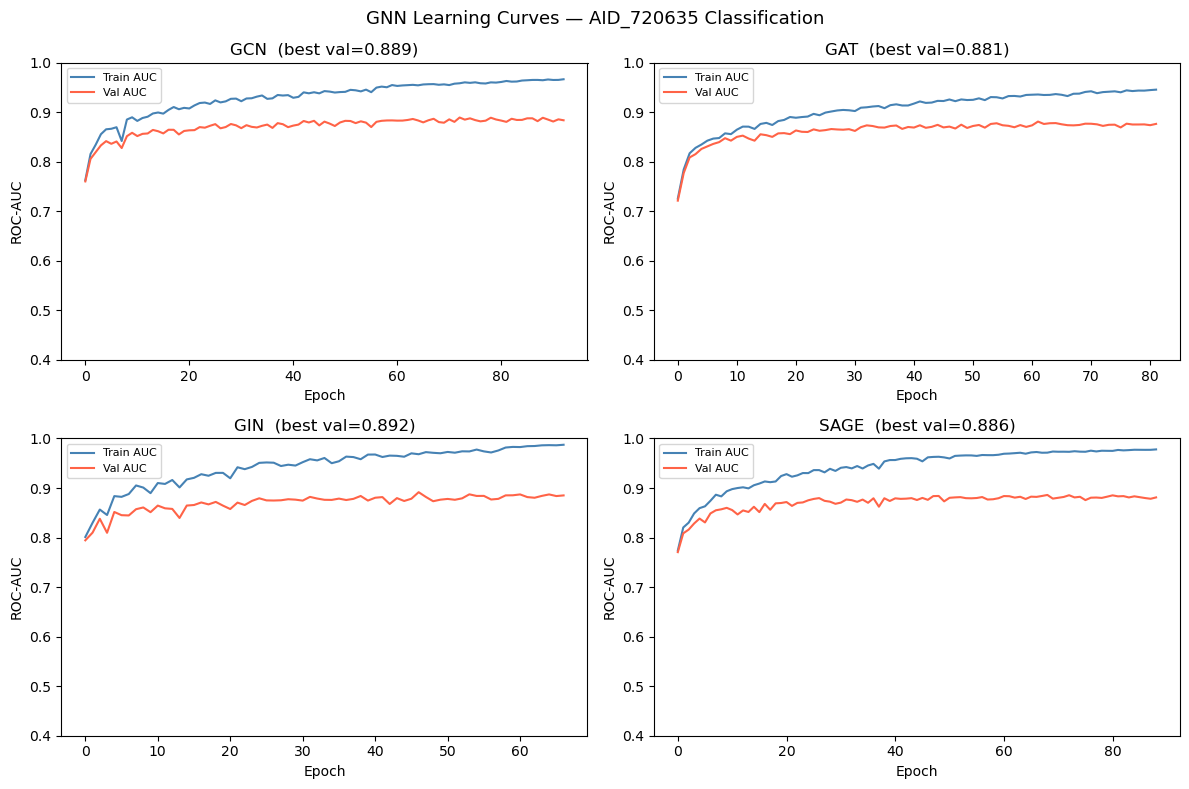

In [28]:
# ── 21. Learning Curves ─────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, arch in zip(axes.ravel(), ['GCN','GAT','GIN','SAGE']):
    if arch in gnn_history:
        tr, va = gnn_history[arch]
        ax.plot(tr, label='Train AUC', color='steelblue')
        ax.plot(va, label='Val AUC',   color='tomato')
        ax.set_title(f'{arch}  (best val={gnn_best_val_auc[arch]:.3f})')
        ax.set_xlabel('Epoch'); ax.set_ylabel('ROC-AUC')
        ax.legend(fontsize=8); ax.set_ylim(0.4, 1.0)
plt.suptitle('GNN Learning Curves — AID_720635 Classification', fontsize=13)
plt.tight_layout(); plt.savefig('gnn_learning_curves.png',dpi=150); plt.show()


In [29]:
# ── 22. GNN Test Evaluation ──────────────────────────────────────────────────
gnn_probs_test = {}

for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads',4)).to(DEVICE)
    model.load_state_dict(state)
    probs, _, _ = gnn_eval(model, test_loader, DEVICE)
    gnn_probs_test[arch] = probs

rows_gnn = []
for arch, prob in gnn_probs_test.items():
    for cpt in [0.5, 0.8]:
        rows_gnn.append(evaluate(y_test, prob, arch, cpt))

df_gnn_test = pd.DataFrame(rows_gnn)[METRIC_COLS]
print('── GNN — Test Set ──')
display(df_gnn_test.set_index(['Model','CPT']))


── GNN — Test Set ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         82.6         82.0  82.3   0.8924  0.7972  0.6134     82.3   
      0.8         66.3         93.8  80.0   0.8924  0.7972  0.6428     80.0   
GAT   0.5         83.7         81.2  82.4   0.8899  0.8019  0.6134     82.4   
      0.8         54.6         96.4  75.5   0.8899  0.8019  0.5972     75.5   
GIN   0.5         84.4         80.1  82.2   0.9005  0.8223  0.6071     82.2   
      0.8         69.1         91.9  80.5   0.9005  0.8223  0.6354     80.5   
SAGE  0.5         84.0         82.4  83.2   0.9001  0.8233  0.6309     83.2   
      0.8         73.8         92.1  82.9   0.9001  0.8233  0.6749     82.9   

               F1  
Model CPT          
GCN   0.5  0.7385  
      0.8  0.7348  
GAT   0.5  0.7387  
      0.8  0.6710  
GIN   0.5  0.7346  
      0.8  0.7372  
SAGE  0.5  0.7500  
      0.8  0.7689

---
## Step 7 — Consensus Model (All Classical + GNN)


In [30]:
# ── 23. Consensus: Average All Model Probabilities ───────────────────────────
all_test_probs = {**cl_probs_test, **gnn_probs_test}

consensus_prob = np.mean(list(all_test_probs.values()), axis=0)
all_test_probs['Consensus'] = consensus_prob

# Classical-only consensus
cl_consensus  = np.mean(list(cl_probs_test.values()), axis=0)
all_test_probs['Consensus-Classical'] = cl_consensus

# GNN-only consensus
gnn_consensus = np.mean(list(gnn_probs_test.values()), axis=0)
all_test_probs['Consensus-GNN'] = gnn_consensus

final_rows = []
for name, prob in all_test_probs.items():
    for cpt in [0.5, 0.8]:
        final_rows.append(evaluate(y_test, prob, name, cpt))

df_final = pd.DataFrame(final_rows)[METRIC_COLS]
print('── FULL TEST SET COMPARISON ──')
display(df_final.set_index(['Model','CPT'])) #to check if we can 3rd categoruy for inactive


── FULL TEST SET COMPARISON ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC  \
Model               CPT                                                    
Random Forest       0.5         81.9         80.2  81.1   0.8893  0.8192   
                    0.8         42.6         98.1  70.3   0.8893  0.8192   
SVM                 0.5         79.4         79.9  79.7   0.8763  0.7643   
                    0.8         55.3         94.4  74.9   0.8763  0.7643   
XGBoost             0.5         81.2         81.2  81.2   0.8795  0.7805   
                    0.8         61.7         91.8  76.7   0.8795  0.7805   
GCN                 0.5         82.6         82.0  82.3   0.8924  0.7972   
                    0.8         66.3         93.8  80.0   0.8924  0.7972   
GAT                 0.5         83.7         81.2  82.4   0.8899  0.8019   
                    0.8         54.6         96.4  75.5   0.8899  0.8019   
GIN                 0.5         84.4         80.1  82.2   0.9005  0.8223   
                    0.8         69.1         91.9  80.5   0.9005  0.8223   
SAGE                0.5         84.0         82.4  83.2   0.9001  0.8233   
                    0.8         73.8         92.1  82.9   0.9001  0.8233   
Consensus           0.5         85.8         83.5  84.7   0.9147  0.8570   
                    0.8         56.4         97.5  76.9   0.9147  0.8570   
Consensus-Classical 0.5         81.9         81.8  81.9   0.8932  0.8197   
                    0.8         52.5         96.3  74.4   0.8932  0.8197   
Consensus-GNN       0.5         84.4         82.1  83.3   0.9073  0.8366   
                    0.8         65.6         95.3  80.5   0.9073  0.8366   

                            MCC  Bal-Acc      F1  
Model               CPT                           
Random Forest       0.5  0.5875     81.1  0.7219  
                    0.8  0.5355     70.3  0.5797  
SVM                 0.5  0.5626     79.7  0.7055  
                    0.8  0.5644     74.9  0.6582  
XGBoost             0.5  0.5922     81.2  0.7247  
                    0.8  0.5719     76.7  0.6837  
GCN                 0.5  0.6134     82.3  0.7385  
                    0.8  0.6428     80.0  0.7348  
GAT                 0.5  0.6134     82.4  0.7387  
                    0.8  0.5972     75.5  0.6710  
GIN                 0.5  0.6071     82.2  0.7346  
                    0.8  0.6354     80.5  0.7372  
SAGE                0.5  0.6309     83.2  0.7500  
                    0.8  0.6749     82.9  0.7689  
Consensus           0.5  0.6588     84.7  0.7683  
                    0.8  0.6335     76.9  0.6958  
Consensus-Classical 0.5  0.6055     81.9  0.7333  
                    0.8  0.5768     74.4  0.6520  
Consensus-GNN       0.5  0.6303     83.3  0.7496  
                    0.8  0.6641     80.5  0.7445

---
## Step 8 — Applicability Domain


AD threshold  : 0.6504
Test in AD    : 514/925 (55.6%)
  AD-filtered Sensitivity: 90.9
  AD-filtered Specificity: 84.8
  AD-filtered CCR: 87.9
  AD-filtered ROC-AUC: 0.9342
  AD-filtered MCC: 0.7417


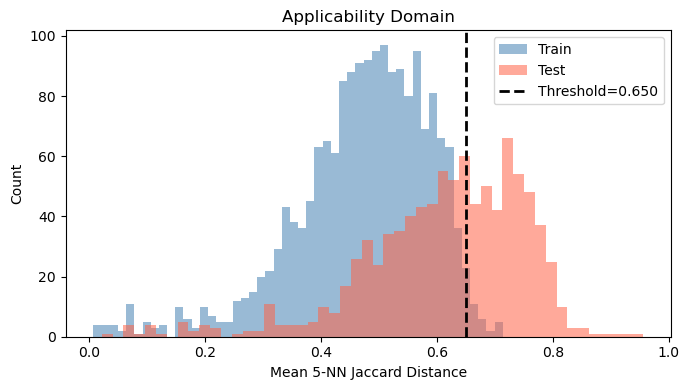

In [31]:
# ── 24. AD — k-NN Jaccard ────────────────────────────────────────────────────
nn_ad = NearestNeighbors(n_neighbors=5, metric='jaccard', n_jobs=-1)
nn_ad.fit(X_train)
d_tr, _ = nn_ad.kneighbors(X_train)
md_tr   = d_tr.mean(axis=1)
ad_thr  = md_tr.mean() + 1.5*md_tr.std()

d_te, _ = nn_ad.kneighbors(X_test)
md_te   = d_te.mean(axis=1)
in_ad   = md_te <= ad_thr
cov     = in_ad.mean()*100

print(f'AD threshold  : {ad_thr:.4f}')
print(f'Test in AD    : {in_ad.sum()}/{len(y_test)} ({cov:.1f}%)')

if in_ad.sum() >= 20:
    m = evaluate(y_test[in_ad], consensus_prob[in_ad], 'Consensus AD', cpt=0.5)
    for k in ['Sensitivity','Specificity','CCR','ROC-AUC','MCC']:
        print(f'  AD-filtered {k}: {m[k]}')

fig, ax = plt.subplots(figsize=(7,4))
ax.hist(md_tr, bins=50, alpha=0.55, color='steelblue', label='Train')
ax.hist(md_te, bins=50, alpha=0.55, color='tomato',    label='Test')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2,
           label=f'Threshold={ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance'); ax.set_ylabel('Count')
ax.set_title('Applicability Domain'); ax.legend()
plt.tight_layout(); plt.savefig('ad_dist.png',dpi=150); plt.show()


---
## Step 9 — Final Summary


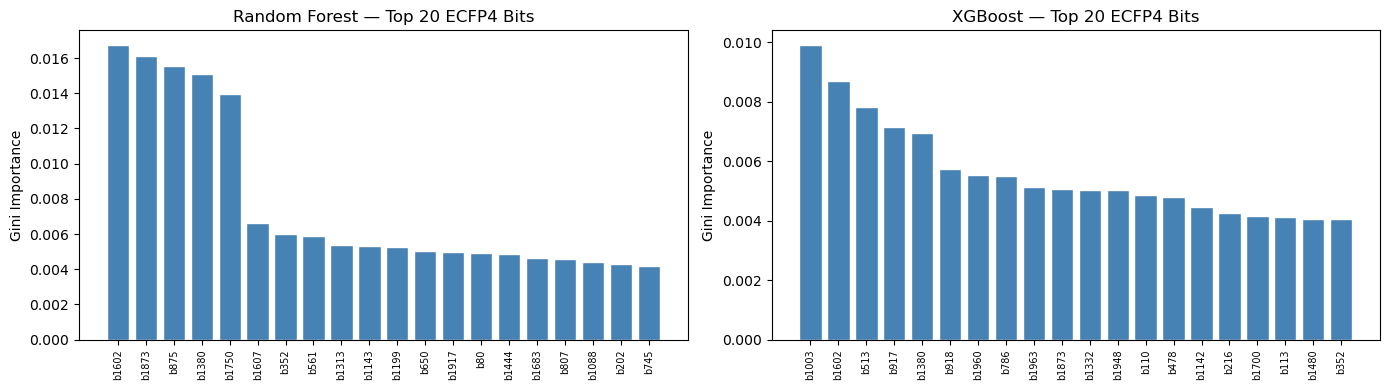

In [32]:
# ── 25. Feature Importance — RF & XGBoost ────────────────────────────────────
fig, axes = plt.subplots(1,2,figsize=(14,4))
for ax,(name,clf) in zip(axes,[('Random Forest',best_rf),('XGBoost',best_xgb)]):
    imp = clf.feature_importances_
    top = np.argsort(imp)[::-1][:20]
    ax.bar(range(20), imp[top], color='steelblue', edgecolor='white')
    ax.set_xticks(range(20))
    ax.set_xticklabels([f'b{i}' for i in top], rotation=90, fontsize=7)
    ax.set_title(f'{name} — Top 20 ECFP4 Bits'); ax.set_ylabel('Gini Importance')
plt.tight_layout(); plt.savefig('feat_importance.png',dpi=150); plt.show()


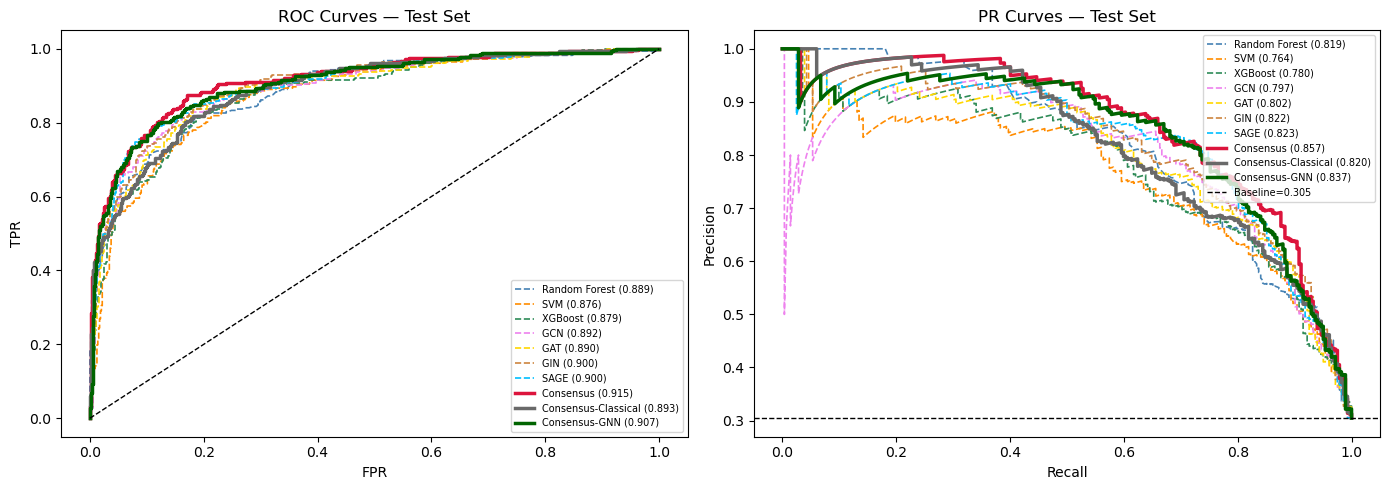

In [33]:
# ── 26. ROC Curves — All Models ──────────────────────────────────────────────
COLORS = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
          'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
          'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1,2,figsize=(14,5))
for name, prob in all_test_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS.get(name,'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr,tpr,_ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    axes[0].plot(fpr,tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre,rec,_ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    axes[1].plot(rec,pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — Test Set'); axes[0].legend(fontsize=7,loc='lower right')

axes[1].axhline(y_test.mean(),color='k',ls='--',lw=1,label=f'Baseline={y_test.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — Test Set'); axes[1].legend(fontsize=7,loc='upper right')

plt.tight_layout(); plt.savefig('roc_pr_all.png',dpi=150); plt.show()


In [34]:
# ── 27. Ranked Summary Table (CPT-1) ─────────────────────────────────────────
summary_cpt1 = df_final[df_final['CPT']==0.5].drop(columns='CPT').set_index('Model')
summary_sorted = summary_cpt1.sort_values('ROC-AUC', ascending=False)
print('═'*90)
print('FINAL RANKING — AID_720635 Binary Toxicity (CPT-1, threshold≥0.50)')
print('80/20/20 split | Hao Zhu downsampling | Morgan ECFP4 + GNN atom/bond features')
print('═'*90)
display(summary_sorted)

print(f'\nApplicability Domain coverage: {cov:.1f}%')
summary_sorted.to_csv('qsar_mito_final_results.csv')
print('Saved → qsar_mito_final_results.csv')


══════════════════════════════════════════════════════════════════════════════════════════
FINAL RANKING — AID_720635 Binary Toxicity (CPT-1, threshold≥0.50)
80/20/20 split | Hao Zhu downsampling | Morgan ECFP4 + GNN atom/bond features
══════════════════════════════════════════════════════════════════════════════════════════


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
Consensus,85.8,83.5,84.7,0.9147,0.8570,0.6588,84.7,0.7683
Consensus-GNN,84.4,82.1,83.3,0.9073,0.8366,0.6303,83.3,0.7496
GIN,84.4,80.1,82.2,0.9005,0.8223,0.6071,82.2,0.7346
SAGE,84.0,82.4,83.2,0.9001,0.8233,0.6309,83.2,0.7500
Consensus-Classical,81.9,81.8,81.9,0.8932,0.8197,0.6055,81.9,0.7333
GCN,82.6,82.0,82.3,0.8924,0.7972,0.6134,82.3,0.7385
GAT,83.7,81.2,82.4,0.8899,0.8019,0.6134,82.4,0.7387
Random Forest,81.9,80.2,81.1,0.8893,0.8192,0.5875,81.1,0.7219
XGBoost,81.2,81.2,81.2,0.8795,0.7805,0.5922,81.2,0.7247



Applicability Domain coverage: 55.6%
Saved → qsar_mito_final_results.csv


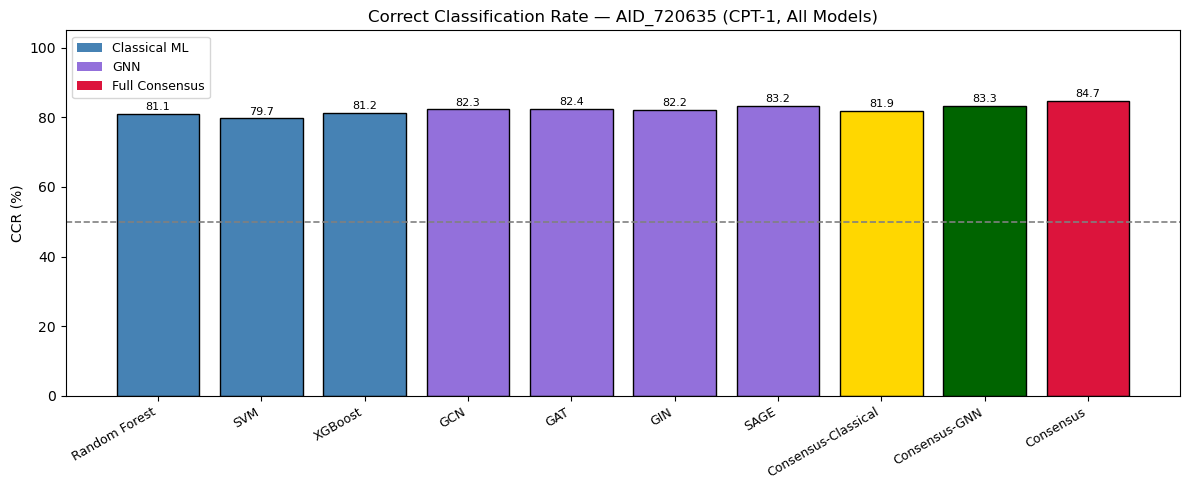

In [35]:
# ── 28. CCR Comparison Bar Chart ─────────────────────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals = [summary_cpt1.loc[m,'CCR'] if m in summary_cpt1.index else 0 for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12,5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0,105)
ax.set_title('Correct Classification Rate — AID_720635 (CPT-1, All Models)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
ax.legend()
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus')]
ax.legend(handles=legend_elements, fontsize=9)
plt.tight_layout(); plt.savefig('ccr_all_models.png',dpi=150); plt.show()


Best model (ROC-AUC): Consensus
              precision    recall  f1-score   support

 Inactive(0)       0.93      0.84      0.88       643
   Active(1)       0.70      0.86      0.77       282

    accuracy                           0.84       925
   macro avg       0.81      0.85      0.82       925
weighted avg       0.86      0.84      0.85       925



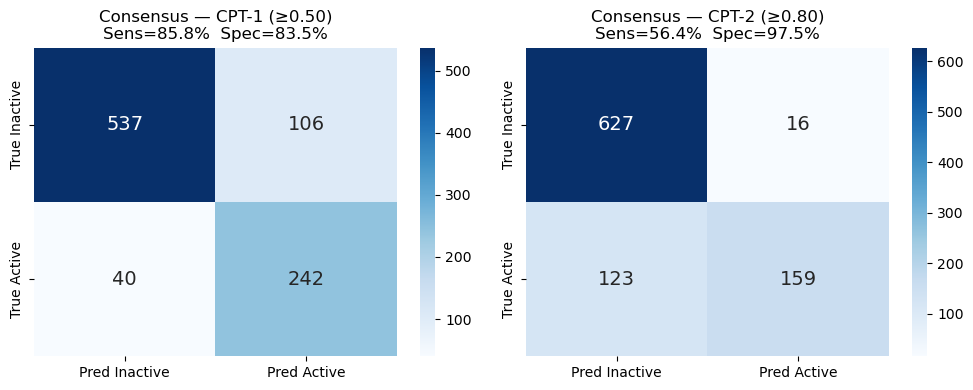

In [36]:
# ── 29. Best Model Report ─────────────────────────────────────────────────────
best_name = summary_sorted.index[0]
best_prob = all_test_probs[best_name]
best_pred = (best_prob >= 0.5).astype(int)
print(f'Best model (ROC-AUC): {best_name}')
print(classification_report(y_test, best_pred, target_names=['Inactive(0)','Active(1)']))

# Confusion matrix
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, cpt, label in zip(axes,[0.5,0.8],['CPT-1 (≥0.50)','CPT-2 (≥0.80)']):
    pred = (consensus_prob >= cpt).astype(int)
    cm   = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred Inactive','Pred Active'],
                yticklabels=['True Inactive','True Active'], annot_kws={'size':14})
    tn,fp,fn,tp = cm.ravel()
    sens = tp/(tp+fn); spec = tn/(tn+fp)
    ax.set_title(f'Consensus — {label}\nSens={sens*100:.1f}%  Spec={spec*100:.1f}%')
plt.tight_layout(); plt.savefig('confusion_final.png',dpi=150); plt.show()


---
## Step 10 — Single Compound Prediction

Paste any SMILES below to run it through all 7 trained models and get a consensus toxicity prediction.


Compound : C1=CC=C(C=C1)C(=O)C2=CC=CC=C2O
Canonical: O=C(c1ccccc1)c1ccccc1O
Mol. Weight: 198.22 Da  |  Atoms: 15

════════════════════════════════════════════════════════════
 INDIVIDUAL MODEL PROBABILITIES (P(Active))
════════════════════════════════════════════════════════════
  Model                   P(Active)    CPT-1    CPT-2
  -------------------------------------------------------
  Random Forest              0.9333   ACTIVE   ACTIVE  
  SVM                        0.8669   ACTIVE   ACTIVE  
  XGBoost                    0.9719   ACTIVE   ACTIVE  
  GCN                        0.9298   ACTIVE   ACTIVE  
  GAT                        0.8233   ACTIVE   ACTIVE  
  GIN                        0.9547   ACTIVE   ACTIVE  
  SAGE                       0.9721   ACTIVE   ACTIVE  
  Consensus-Classical        0.9240   ACTIVE   ACTIVE  
  Consensus-GNN              0.9200   ACTIVE   ACTIVE  
  CONSENSUS (all 7)          0.9217   ACTIVE   ACTIVE  ◄◄
══════════════════════════════════════════════

[12:59:22] DEPRECATION WARNING: please use MorganGenerator


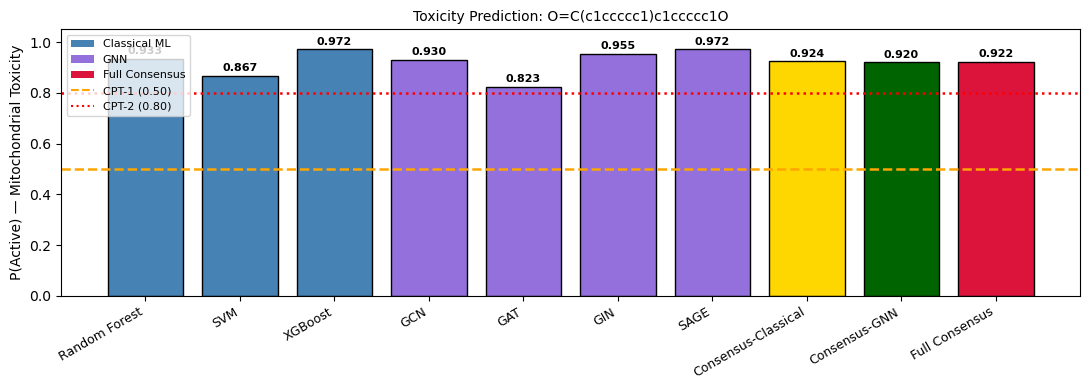

In [37]:
# ── 30. Single Compound Prediction ───────────────────────────────────────────
# ► Change TEST_SMILES to any molecule you want to predict.
# ► Set TRUE_LABEL = 1 (Active) or 0 (Inactive) if you know it, else None.
# ─────────────────────────────────────────────────────────────────────────────

from rdkit.Chem import Descriptors   # needed for MolWt

TEST_SMILES  = "C1=CC=C(C=C1)C(=O)C2=CC=CC=C2O"  
TRUE_LABEL   = None                       

# ── Step A: Parse & canonicalise ─────────────────────────────────────────────
mol = Chem.MolFromSmiles(TEST_SMILES)
if mol is None:
    raise ValueError(f"RDKit could not parse SMILES: {TEST_SMILES!r}  — check for typos.")

canon = Chem.MolToSmiles(mol)
mw    = Descriptors.MolWt(mol)
print(f"Compound : {TEST_SMILES}")
print(f"Canonical: {canon}")
print(f"Mol. Weight: {mw:.2f} Da  |  Atoms: {mol.GetNumAtoms()}")

# ── Step B: Morgan fingerprint (for classical ML + AD) ────────────────────────
fp_arr = smiles_to_ecfp4(canon)          # reuses function from Cell 5
X_query = fp_arr.reshape(1, -1)          # shape (1, 2048)

# ── Step C: Build graph (for GNN) ─────────────────────────────────────────────
graph_query = mol_to_graph(canon, label=0)   # label=0 is placeholder
query_loader = DataLoader([graph_query], batch_size=1, shuffle=False)

# ── Step D: Classical ML probabilities ────────────────────────────────────────
cl_query_probs = {}
for name, clf in classical.items():                # RF, SVM, XGBoost
    cl_query_probs[name] = float(clf.predict_proba(X_query)[0, 1])

# ── Step E: GNN probabilities ─────────────────────────────────────────────────
gnn_query_probs = {}
for arch, state in gnn_best_models.items():        # GCN, GAT, GIN, SAGE
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads', 4)).to(DEVICE)
    model.load_state_dict(state)
    model.eval()
    with torch.no_grad():
        batch = next(iter(query_loader)).to(DEVICE)
        logit = model(batch.x, batch.edge_index, batch.batch)
        gnn_query_probs[arch] = float(torch.sigmoid(logit).item())

# ── Step F: Consensus ─────────────────────────────────────────────────────────
all_query_probs = {**cl_query_probs, **gnn_query_probs}
consensus_q     = float(np.mean(list(all_query_probs.values())))
cl_consensus_q  = float(np.mean(list(cl_query_probs.values())))
gnn_consensus_q = float(np.mean(list(gnn_query_probs.values())))

# ── Step G: Applicability Domain check ───────────────────────────────────────
d_query, _ = nn_ad.kneighbors(X_query)
md_query   = float(d_query.mean())
in_domain  = md_query <= ad_thr

# ── Step H: Pretty print ─────────────────────────────────────────────────────
print("\n" + "═"*60)
print(" INDIVIDUAL MODEL PROBABILITIES (P(Active))")
print("═"*60)
print(f"  {'Model':<22} {'P(Active)':>10}  {'CPT-1':>7}  {'CPT-2':>7}")
print("  " + "-"*55)
for name, p in {**all_query_probs,
                'Consensus-Classical': cl_consensus_q,
                'Consensus-GNN'      : gnn_consensus_q,
                'CONSENSUS (all 7)'  : consensus_q}.items():
    pred1 = "ACTIVE" if p >= 0.5 else "inactive"
    pred2 = "ACTIVE" if p >= 0.8 else "inactive"
    marker = "◄◄" if "CONSENSUS" in name else ""
    print(f"  {name:<22} {p:>10.4f}  {pred1:>7}  {pred2:>7}  {marker}")

print("═"*60)
print(f"\n  CONSENSUS PROBABILITY : {consensus_q:.4f}")

cpt1_call = "⚠  ACTIVE (Mitochondrially Toxic)" if consensus_q >= 0.5 else "✓  INACTIVE (Non-Toxic)"
cpt2_call = "⚠  ACTIVE (High-confidence)"        if consensus_q >= 0.8 else "✓  INACTIVE / uncertain"

print(f"  CPT-1 (≥0.50) verdict: {cpt1_call}")
print(f"  CPT-2 (≥0.80) verdict: {cpt2_call}")

ad_msg = f"INSIDE applicability domain  (dist={md_query:.4f} ≤ {ad_thr:.4f})" \
         if in_domain else \
         f"OUTSIDE applicability domain (dist={md_query:.4f} > {ad_thr:.4f}) — prediction may be unreliable"
print(f"\n  AD check   : {ad_msg}")

if TRUE_LABEL is not None:
    lbl_str = "Active (1)" if TRUE_LABEL == 1 else "Inactive (0)"
    correct = (consensus_q >= 0.5) == (TRUE_LABEL == 1)
    print(f"\n  True label : {lbl_str}  →  Prediction {'CORRECT ✓' if correct else 'WRONG ✗'}")

print("═"*60)

# ── Step I: Bar chart ─────────────────────────────────────────────────────────
plot_names  = list(all_query_probs.keys()) + ['Consensus-Classical','Consensus-GNN','Full Consensus']
plot_probs  = list(all_query_probs.values()) + [cl_consensus_q, gnn_consensus_q, consensus_q]
plot_colors = (['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson'])

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(plot_names, plot_probs, color=plot_colors, edgecolor='black')
ax.axhline(0.5, color='orange', lw=1.8, ls='--', label='CPT-1 (0.50)')
ax.axhline(0.8, color='red',    lw=1.8, ls=':',  label='CPT-2 (0.80)')
for b, p in zip(bars, plot_probs):
    ax.text(b.get_x() + b.get_width()/2, p + 0.01, f'{p:.3f}',
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.set_ylabel('P(Active) — Mitochondrial Toxicity')
ax.set_title(f'Toxicity Prediction: {canon}', fontsize=10)
ax.set_xticklabels(plot_names, rotation=30, ha='right', fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='steelblue',label='Classical ML'),
                   Patch(facecolor='mediumpurple',label='GNN'),
                   Patch(facecolor='crimson',label='Full Consensus'),
                   plt.Line2D([0],[0],color='orange',ls='--',label='CPT-1 (0.50)'),
                   plt.Line2D([0],[0],color='red',   ls=':' ,label='CPT-2 (0.80)')],
          fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig('single_compound_prediction.png', dpi=150)
plt.show()


---
## Step 11 — External Test Set: In Vivo Liver Injury (LTKB-BD DILI)

Three PubChem bioassays from the FDA's Liver Toxicity Knowledge Base (LTKB-BD):

| Assay | DILI Category | LTKB Severity Score | Description |
|-------|--------------|---------------------|-------------|
| AID_625276 | Most-concern | 7–8 | Fatal hepatotoxicity, acute liver failure |
| AID_625277 | Less-concern | 2–5 | Aminotransferases increase, jaundice, cholestasis |
| AID_625278 | No-concern | — | Not applicable (negative controls) |

**DILI binary label**: 1 = DILI concern (scored entries in AID_625276/625277), 0 = no concern (AID_625278).  
"Not applicable" entries in AID_625276/625277 are dropped (ambiguous).

**Goal**: Test whether the AID_720635 mitotoxicity QSAR model (ECFP4 + GNN) translates to in vivo DILI prediction — a genuinely independent external evaluation across a biological endpoint gap.


In [38]:
# ── E1. Load & Label Liver DILI Data ─────────────────────────────────────────
cols_keep = ['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES',
             'dili_label', 'dili_source', 'dili_severity_score', 'Activity Comment']
liver_dfs = []

# AID_625276 — Most-concern DILI (fatal hepatotoxicity / acute liver failure; scores 7–8)
df76 = pd.read_csv('liver/AID_625276_datatable.csv', low_memory=False)
df76 = df76[df76['Standard Type'] == 'LTKB_BD DILI severity score'].copy()
df76['dili_severity_score'] = pd.to_numeric(df76['Standard Value'], errors='coerce')
df76['dili_label']   = df76['dili_severity_score'].apply(lambda v: 1 if pd.notna(v) else np.nan)
df76['dili_source']  = 'AID_625276 (Most-concern)'
df76 = df76[df76['dili_label'].notna()].copy()
df76['dili_label']   = df76['dili_label'].astype(int)
liver_dfs.append(df76[cols_keep])

# AID_625277 — Less-concern DILI (aminotransferases / jaundice / cholestasis; scores 2–5)
df77 = pd.read_csv('liver/AID_625277_datatable.csv', low_memory=False)
df77 = df77[df77['Standard Type'] == 'LTKB_BD DILI severity score'].copy()
df77['dili_severity_score'] = pd.to_numeric(df77['Standard Value'], errors='coerce')
df77['dili_label']   = df77['dili_severity_score'].apply(lambda v: 1 if pd.notna(v) else np.nan)
df77['dili_source']  = 'AID_625277 (Less-concern)'
df77 = df77[df77['dili_label'].notna()].copy()
df77['dili_label']   = df77['dili_label'].astype(int)
liver_dfs.append(df77[cols_keep])

# AID_625278 — No-concern DILI (all "not applicable" → label = 0)
df78 = pd.read_csv('liver/AID_625278_datatable.csv', low_memory=False)
df78 = df78[df78['Standard Type'] == 'LTKB_BD DILI severity score'].copy()
df78['dili_label']          = 0
df78['dili_source']         = 'AID_625278 (No-concern)'
df78['dili_severity_score'] = np.nan
liver_dfs.append(df78[cols_keep])

df_liver = pd.concat(liver_dfs, ignore_index=True)

# Canonicalize SMILES, drop invalids, deduplicate
df_liver['csmi'] = df_liver['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(canonicalize)
df_liver = df_liver.dropna(subset=['csmi']).reset_index(drop=True)
df_liver = df_liver.drop_duplicates('csmi', keep='first').reset_index(drop=True)

pos = (df_liver['dili_label'] == 1).sum()
neg = (df_liver['dili_label'] == 0).sum()
print(f'DILI External Test Set')
print(f'  Total compounds  : {len(df_liver):,}')
print(f'  DILI concern  (1): {pos:,}')
print(f'  No concern    (0): {neg:,}')
print(f'  Imbalance ratio  : {neg/pos:.2f}:1')
print(f'\nBreakdown by source:')
print(df_liver.groupby('dili_source')['dili_label'].value_counts().to_string())


[12:59:23] SMILES Parse Error: syntax error while parsing: nan
[12:59:23] SMILES Parse Error: check for mistakes around position 2:
[12:59:23] nan
[12:59:23] ~^
[12:59:23] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[12:59:23] SMILES Parse Error: syntax error while parsing: nan
[12:59:23] SMILES Parse Error: check for mistakes around position 2:
[12:59:23] nan
[12:59:23] ~^
[12:59:23] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[12:59:23] SMILES Parse Error: syntax error while parsing: nan
[12:59:23] SMILES Parse Error: check for mistakes around position 2:
[12:59:23] nan
[12:59:23] ~^
[12:59:23] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'


DILI External Test Set
  Total compounds  : 218
  DILI concern  (1): 157
  No concern    (0): 61
  Imbalance ratio  : 0.39:1

Breakdown by source:
dili_source                dili_label
AID_625276 (Most-concern)  1             74
AID_625277 (Less-concern)  1             83
AID_625278 (No-concern)    0             61


[12:59:23] SMILES Parse Error: syntax error while parsing: nan
[12:59:23] SMILES Parse Error: check for mistakes around position 2:
[12:59:23] nan
[12:59:23] ~^
[12:59:23] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[12:59:23] SMILES Parse Error: syntax error while parsing: nan
[12:59:23] SMILES Parse Error: check for mistakes around position 2:
[12:59:23] nan
[12:59:23] ~^
[12:59:23] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[12:59:23] SMILES Parse Error: syntax error while parsing: nan
[12:59:23] SMILES Parse Error: check for mistakes around position 2:
[12:59:23] nan
[12:59:23] ~^
[12:59:23] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'
[12:59:23] SMILES Parse Error: syntax error while parsing: nan
[12:59:23] SMILES Parse Error: check for mistakes around position 2:
[12:59:23] nan
[12:59:23] ~^
[12:59:23] SMILES Parse Error: Failed parsing SMILES 'nan' for input: 'nan'


In [39]:
# ── E2. Overlap Check: Liver CIDs vs Mito Training Set ───────────────────────
mito_cids  = set(df['PUBCHEM_CID'].dropna().astype(int).tolist())   # full AID_720635 set
liver_cids = set(df_liver['PUBCHEM_CID'].dropna().astype(int).tolist())

overlap      = mito_cids & liver_cids
overlap_pct  = 100 * len(overlap) / len(liver_cids) if liver_cids else 0

print(f'AID_720635 (mito) compounds : {len(mito_cids):,}')
print(f'Liver DILI compounds        : {len(liver_cids):,}')
print(f'CID overlap                 : {len(overlap):,}  ({overlap_pct:.1f}% of liver set)')
print(f'Truly external (no overlap) : {len(liver_cids)-len(overlap):,}  ({100-overlap_pct:.1f}%)')

if len(overlap) > 0:
    ov_df = df_liver[df_liver['PUBCHEM_CID'].isin(overlap)]
    print(f'\nDILI labels among overlapping compounds:')
    print(ov_df['dili_label'].value_counts().to_string())
    print('(Even overlapping CIDs are treated as external — different endpoint: DILI vs mitotoxicity)')


AID_720635 (mito) compounds : 4,625
Liver DILI compounds        : 218
CID overlap                 : 65  (29.8% of liver set)
Truly external (no overlap) : 153  (70.2%)

DILI labels among overlapping compounds:
dili_label
1    51
0    14
(Even overlapping CIDs are treated as external — different endpoint: DILI vs mitotoxicity)


In [40]:
# ── E3. ECFP4 Fingerprints + Graphs for Liver Compounds ──────────────────────
liver_fps_raw = df_liver['csmi'].apply(smiles_to_ecfp4)
valid_fp      = liver_fps_raw.notna()
df_liver      = df_liver[valid_fp].reset_index(drop=True)
X_liver       = np.vstack(liver_fps_raw[valid_fp].values)
y_liver       = df_liver['dili_label'].values

# Build molecular graphs (same features as training)
graphs_liver, valid_graph_idx = [], []
for i, (smi, lbl) in enumerate(zip(df_liver['csmi'].values, y_liver)):
    g = mol_to_graph(smi, lbl)
    if g is not None:
        graphs_liver.append(g)
        valid_graph_idx.append(i)

valid_graph_idx = np.array(valid_graph_idx)
X_liver_gnn    = X_liver[valid_graph_idx]
y_liver_gnn    = y_liver[valid_graph_idx]
df_liver_gnn   = df_liver.iloc[valid_graph_idx].reset_index(drop=True)
liver_loader   = DataLoader(graphs_liver, batch_size=64, shuffle=False)

print(f'Liver fingerprint matrix : {X_liver.shape}')
print(f'Valid graphs             : {len(graphs_liver)} / {len(df_liver)}')
print(f'FP density — liver       : {X_liver.mean():.4f}  (train: {X_train.mean():.4f})')
print(f'DILI concern in GNN set  : {(y_liver_gnn==1).sum()} / {len(y_liver_gnn)}')


Liver fingerprint matrix : (218, 2048)
Valid graphs             : 218 / 218
FP density — liver       : 0.0195  (train: 0.0150)
DILI concern in GNN set  : 157 / 218


[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerator
[12:59:23] DEPRECATION WARNING: please use MorganGenerat

AD threshold              : 0.6504
Liver compounds in AD     : 98/218 (45.0%)
  DILI-concern (1) in AD  : 68 / 157
  No-concern   (0) in AD  : 30 / 61


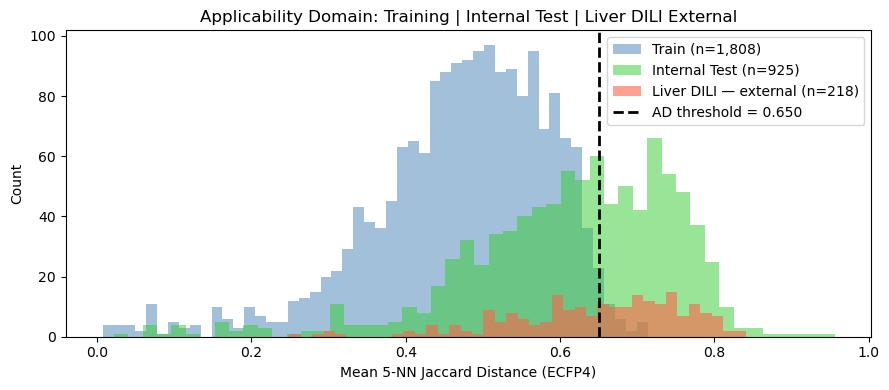

In [41]:
# ── E4. Applicability Domain — Liver Compounds ────────────────────────────────
d_liver, _   = nn_ad.kneighbors(X_liver)
md_liver     = d_liver.mean(axis=1)
in_ad_liver  = md_liver <= ad_thr

print(f'AD threshold              : {ad_thr:.4f}')
print(f'Liver compounds in AD     : {in_ad_liver.sum()}/{len(y_liver)} ({in_ad_liver.mean()*100:.1f}%)')
print(f'  DILI-concern (1) in AD  : {(in_ad_liver & (y_liver==1)).sum()} / {(y_liver==1).sum()}')
print(f'  No-concern   (0) in AD  : {(in_ad_liver & (y_liver==0)).sum()} / {(y_liver==0).sum()}')

fig, ax = plt.subplots(figsize=(9,4))
ax.hist(md_tr,    bins=50, alpha=0.5, color='steelblue', label=f'Train (n={len(md_tr):,})')
ax.hist(md_te,    bins=50, alpha=0.5, color='limegreen', label=f'Internal Test (n={len(md_te):,})')
ax.hist(md_liver, bins=40, alpha=0.6, color='tomato',    label=f'Liver DILI — external (n={len(md_liver):,})')
ax.axvline(ad_thr, color='black', linestyle='--', lw=2, label=f'AD threshold = {ad_thr:.3f}')
ax.set_xlabel('Mean 5-NN Jaccard Distance (ECFP4)')
ax.set_ylabel('Count')
ax.set_title('Applicability Domain: Training | Internal Test | Liver DILI External')
ax.legend(); plt.tight_layout()
plt.savefig('ad_liver_external.png', dpi=150); plt.show()


In [42]:
# ── E5. Classical ML — Liver DILI Evaluation ─────────────────────────────────
cl_probs_liver = {n: clf.predict_proba(X_liver)[:,1] for n, clf in classical.items()}

rows_liver_cl = []
for name in classical:
    for cpt in [0.5, 0.8]:
        rows_liver_cl.append(evaluate(y_liver, cl_probs_liver[name], name, cpt))

df_liver_cl = pd.DataFrame(rows_liver_cl)[METRIC_COLS]
print('── Classical ML — Liver DILI External Test ──')
display(df_liver_cl.set_index(['Model','CPT']))


── Classical ML — Liver DILI External Test ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  \
Model         CPT                                                            
Random Forest 0.5         47.1         75.4  61.3   0.6373  0.8128  0.2059   
              0.8         12.7         93.4  53.1   0.6373  0.8128  0.0887   
SVM           0.5         42.7         73.8  58.2   0.6341  0.8075  0.1520   
              0.8         22.3         86.9  54.6   0.6341  0.8075  0.1035   
XGBoost       0.5         49.7         80.3  65.0   0.6808  0.8477  0.2736   
              0.8         26.1         90.2  58.1   0.6808  0.8477  0.1777   

                   Bal-Acc      F1  
Model         CPT                   
Random Forest 0.5     61.3  0.6016  
              0.8     53.1  0.2210  
SVM           0.5     58.2  0.5583  
              0.8     54.6  0.3500  
XGBoost       0.5     65.0  0.6316  
              0.8     58.1  0.4020

In [43]:
# ── E6. GNN — Liver DILI Evaluation ──────────────────────────────────────────
gnn_probs_liver = {}
for arch, state in gnn_best_models.items():
    cfg   = gnn_best_configs[arch]
    model = MolGNN(ATOM_DIM, hidden=cfg['hidden'], n_layers=cfg['n_layers'],
                   dropout=cfg['dropout'], conv_type=arch,
                   heads=cfg.get('heads', 4)).to(DEVICE)
    model.load_state_dict(state)
    probs_g, _, _ = gnn_eval(model, liver_loader, DEVICE)
    gnn_probs_liver[arch] = probs_g

rows_liver_gnn = []
for arch, prob in gnn_probs_liver.items():
    for cpt in [0.5, 0.8]:
        rows_liver_gnn.append(evaluate(y_liver_gnn, prob, arch, cpt))

df_liver_gnn_res = pd.DataFrame(rows_liver_gnn)[METRIC_COLS]
print('── GNN — Liver DILI External Test ──')
display(df_liver_gnn_res.set_index(['Model','CPT']))


── GNN — Liver DILI External Test ──


Sensitivity  Specificity   CCR  ROC-AUC  PR-AUC     MCC  Bal-Acc  \
Model CPT                                                                     
GCN   0.5         37.6         85.2  61.4   0.6609  0.8350  0.2212     61.4   
      0.8         19.7         95.1  57.4   0.6609  0.8350  0.1835     57.4   
GAT   0.5         40.1         82.0  61.0   0.6465  0.8358  0.2095     61.0   
      0.8         13.4         96.7  55.0   0.6465  0.8358  0.1475     55.0   
GIN   0.5         47.1         78.7  62.9   0.6851  0.8422  0.2367     62.9   
      0.8         26.1         91.8  59.0   0.6851  0.8422  0.1971     59.0   
SAGE  0.5         43.9         68.9  56.4   0.6459  0.8143  0.1171     56.4   
      0.8         24.2         95.1  59.6   0.6459  0.8143  0.2216     59.6   

               F1  
Model CPT          
GCN   0.5  0.5244  
      0.8  0.3246  
GAT   0.5  0.5455  
      0.8  0.2333  
GIN   0.5  0.6066  
      0.8  0.4039  
SAGE  0.5  0.5633  
      0.8  0.3838

In [44]:
# ── E7. Consensus — Liver DILI Full Summary ───────────────────────────────────
# Use GNN-valid subset for all models to ensure consistent sample sizes
cl_probs_liver_gnn = {n: clf.predict_proba(X_liver_gnn)[:,1] for n, clf in classical.items()}
all_liver_probs    = {**cl_probs_liver_gnn, **gnn_probs_liver}

liver_consensus     = np.mean(list(all_liver_probs.values()), axis=0)
liver_cl_consensus  = np.mean(list(cl_probs_liver_gnn.values()), axis=0)
liver_gnn_consensus = np.mean(list(gnn_probs_liver.values()), axis=0)

all_liver_probs['Consensus']           = liver_consensus
all_liver_probs['Consensus-Classical'] = liver_cl_consensus
all_liver_probs['Consensus-GNN']       = liver_gnn_consensus

final_liver_rows = []
for name, prob in all_liver_probs.items():
    for cpt in [0.5, 0.8]:
        final_liver_rows.append(evaluate(y_liver_gnn, prob, name, cpt))

df_liver_final = pd.DataFrame(final_liver_rows)[METRIC_COLS]
summary_liver  = df_liver_final[df_liver_final['CPT'] == 0.5].set_index('Model').drop(columns='CPT')
summary_liver_sorted = summary_liver.sort_values('ROC-AUC', ascending=False)

print('='*90)
print('EXTERNAL TEST SET — LIVER DILI (LTKB-BD, AID_625276/625277/625278)')
print('Model trained on: AID_720635 (Mitochondrial Toxicity) | ECFP4 + GNN atom/bond features')
print('='*90)
display(summary_liver_sorted)
summary_liver_sorted.to_csv('liver_dili_external_results.csv')
print('Saved → liver_dili_external_results.csv')


EXTERNAL TEST SET — LIVER DILI (LTKB-BD, AID_625276/625277/625278)
Model trained on: AID_720635 (Mitochondrial Toxicity) | ECFP4 + GNN atom/bond features


,Sensitivity,Specificity,CCR,ROC-AUC,PR-AUC,MCC,Bal-Acc,F1
Model,,,,,,,,
GIN,47.1,78.7,62.9,0.6851,0.8422,0.2367,62.9,0.6066
XGBoost,49.7,80.3,65.0,0.6808,0.8477,0.2736,65.0,0.6316
Consensus,41.4,80.3,60.9,0.6725,0.8392,0.2041,60.9,0.5556
Consensus-GNN,40.8,82.0,61.4,0.6666,0.8405,0.2148,61.4,0.5517
GCN,37.6,85.2,61.4,0.6609,0.8350,0.2212,61.4,0.5244
Consensus-Classical,45.2,78.7,62.0,0.6593,0.8244,0.2206,62.0,0.5892
GAT,40.1,82.0,61.0,0.6465,0.8358,0.2095,61.0,0.5455
SAGE,43.9,68.9,56.4,0.6459,0.8143,0.1171,56.4,0.5633
Random Forest,47.1,75.4,61.3,0.6373,0.8128,0.2059,61.3,0.6016


Saved → liver_dili_external_results.csv


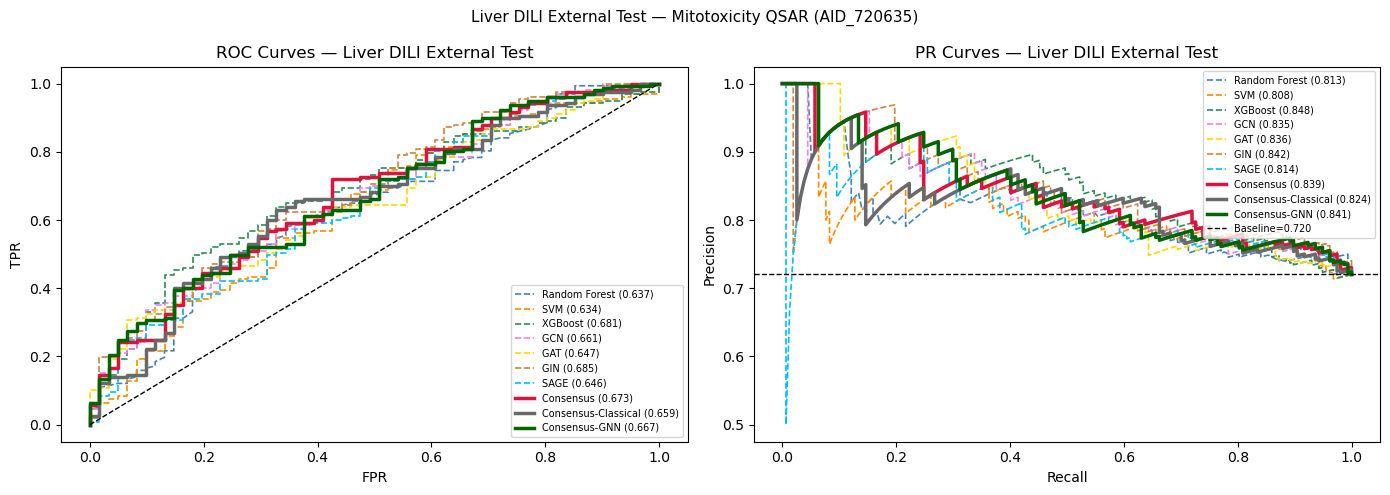

In [45]:
# ── E8. ROC / PR Curves — Liver DILI External Test ───────────────────────────
COLORS_L = {'Random Forest':'steelblue','SVM':'darkorange','XGBoost':'seagreen',
            'GCN':'violet','GAT':'gold','GIN':'peru','SAGE':'deepskyblue',
            'Consensus':'crimson','Consensus-Classical':'dimgray','Consensus-GNN':'darkgreen'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, prob in all_liver_probs.items():
    lw = 2.5 if 'Consensus' in name else 1.2
    c  = COLORS_L.get(name, 'gray')
    ls = '-' if name in ['Consensus','Consensus-Classical','Consensus-GNN'] else '--'
    fpr, tpr, _ = roc_curve(y_liver_gnn, prob)
    auc = roc_auc_score(y_liver_gnn, prob)
    axes[0].plot(fpr, tpr, lw=lw, color=c, ls=ls, label=f'{name} ({auc:.3f})')
    pre, rec, _ = precision_recall_curve(y_liver_gnn, prob)
    ap = average_precision_score(y_liver_gnn, prob)
    axes[1].plot(rec, pre, lw=lw, color=c, ls=ls, label=f'{name} ({ap:.3f})')

axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC Curves — Liver DILI External Test')
axes[0].legend(fontsize=7, loc='lower right')

axes[1].axhline(y_liver_gnn.mean(), color='k', ls='--', lw=1,
                label=f'Baseline={y_liver_gnn.mean():.3f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('PR Curves — Liver DILI External Test')
axes[1].legend(fontsize=7, loc='upper right')

plt.suptitle('Liver DILI External Test — Mitotoxicity QSAR (AID_720635)', fontsize=11)
plt.tight_layout(); plt.savefig('roc_pr_liver_external.png', dpi=150); plt.show()


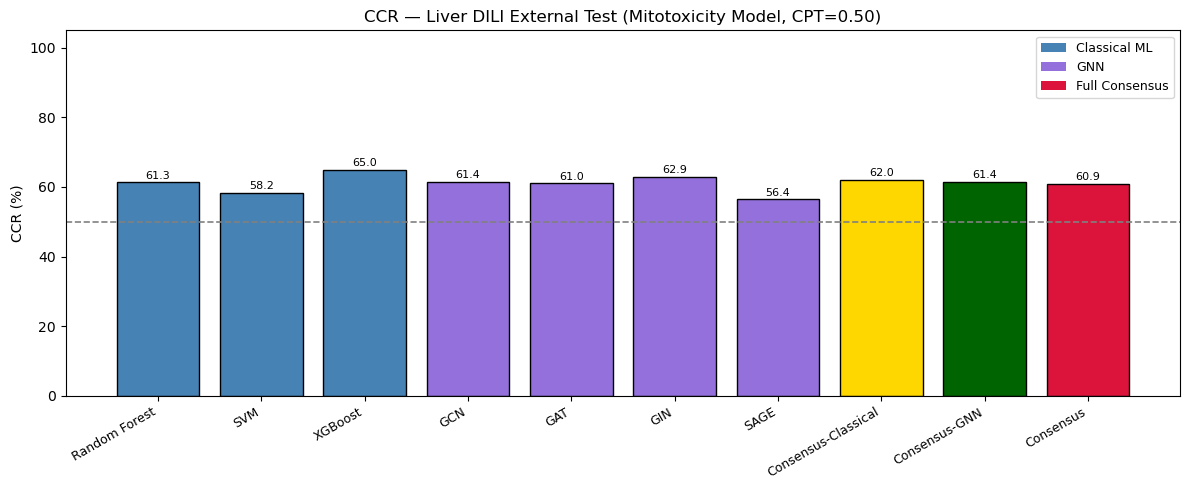


AD-filtered: 98 / 218 liver compounds inside AD (45.0%)
  Sensitivity  : 51.5%
  Specificity  : 76.7%
  CCR          : 64.1%
  ROC-AUC      : 0.6995
  MCC          : 0.262


In [46]:
# ── E9. CCR Bar Chart + AD-Filtered Evaluation ────────────────────────────────
models_to_plot = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE',
                  'Consensus-Classical','Consensus-GNN','Consensus']
ccr_vals   = [summary_liver.loc[m,'CCR'] if m in summary_liver.index else 0
              for m in models_to_plot]
colors_bar = ['steelblue']*3 + ['mediumpurple']*4 + ['gold','darkgreen','crimson']

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(models_to_plot, ccr_vals, color=colors_bar, edgecolor='black')
ax.axhline(50, color='gray', linestyle='--', lw=1.2, label='Chance (50%)')
ax.set_ylabel('CCR (%)'); ax.set_ylim(0, 105)
ax.set_title('CCR — Liver DILI External Test (Mitotoxicity Model, CPT=0.50)')
ax.set_xticklabels(models_to_plot, rotation=30, ha='right', fontsize=9)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=8)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor='steelblue', label='Classical ML'),
                   Patch(facecolor='mediumpurple', label='GNN'),
                   Patch(facecolor='crimson', label='Full Consensus')], fontsize=9)
plt.tight_layout(); plt.savefig('ccr_liver_external.png', dpi=150); plt.show()

# AD-filtered evaluation
in_ad_liver_gnn = in_ad_liver[valid_graph_idx]
n_in_ad = in_ad_liver_gnn.sum()
print(f'\nAD-filtered: {n_in_ad} / {len(y_liver_gnn)} liver compounds inside AD ({n_in_ad/len(y_liver_gnn)*100:.1f}%)')
if n_in_ad >= 10:
    m_ad = evaluate(y_liver_gnn[in_ad_liver_gnn],
                    liver_consensus[in_ad_liver_gnn], 'Consensus (AD-filtered)')
    print(f'  Sensitivity  : {m_ad["Sensitivity"]}%')
    print(f'  Specificity  : {m_ad["Specificity"]}%')
    print(f'  CCR          : {m_ad["CCR"]}%')
    print(f'  ROC-AUC      : {m_ad["ROC-AUC"]}')
    print(f'  MCC          : {m_ad["MCC"]}')
else:
    print('  Too few AD-filtered compounds for meaningful evaluation.')


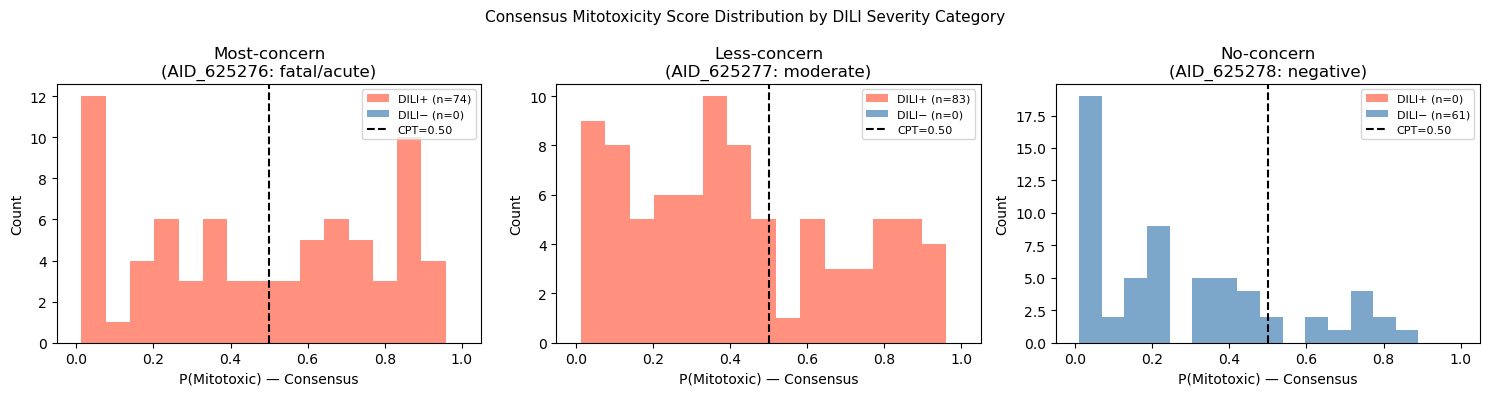

Spearman rho (DILI severity score vs P(mitotoxic)): 0.034  (p=0.6737)
Interpretation: positive correlation between in vitro mitotoxicity prediction and in vivo DILI severity.


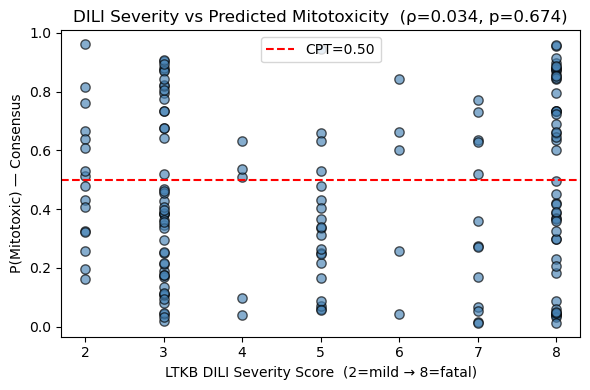

In [47]:
# ── E10. Per-Severity Breakdown ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
categories = {
    'Most-concern\n(AID_625276: fatal/acute)': df_liver_gnn['dili_source'].str.contains('AID_625276'),
    'Less-concern\n(AID_625277: moderate)':    df_liver_gnn['dili_source'].str.contains('AID_625277'),
    'No-concern\n(AID_625278: negative)':       df_liver_gnn['dili_source'].str.contains('AID_625278'),
}

for ax, (title, mask) in zip(axes, categories.items()):
    mask_arr = mask.values
    p = liver_consensus[mask_arr]
    y = y_liver_gnn[mask_arr]
    ax.hist(p[y==1], bins=15, alpha=0.7, color='tomato',   label=f'DILI+ (n={y.sum()})')
    ax.hist(p[y==0], bins=15, alpha=0.7, color='steelblue',label=f'DILI− (n={(y==0).sum()})')
    ax.axvline(0.5, color='black', ls='--', lw=1.5, label='CPT=0.50')
    ax.set_xlabel('P(Mitotoxic) — Consensus'); ax.set_ylabel('Count')
    ax.set_title(title); ax.legend(fontsize=8)

plt.suptitle('Consensus Mitotoxicity Score Distribution by DILI Severity Category', fontsize=11)
plt.tight_layout(); plt.savefig('liver_dili_score_dist.png', dpi=150); plt.show()

# Spearman correlation: DILI severity score vs predicted mitotoxicity probability
sev_mask = df_liver_gnn['dili_severity_score'].notna()
if sev_mask.sum() > 5:
    from scipy.stats import spearmanr
    sev_scores = df_liver_gnn.loc[sev_mask, 'dili_severity_score'].values
    pred_probs  = liver_consensus[sev_mask.values]
    rho, pval   = spearmanr(sev_scores, pred_probs)
    print(f'Spearman rho (DILI severity score vs P(mitotoxic)): {rho:.3f}  (p={pval:.4f})')
    print(f'Interpretation: {"positive correlation" if rho>0 else "no/negative correlation"} '
          f'between in vitro mitotoxicity prediction and in vivo DILI severity.')

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(sev_scores, pred_probs, alpha=0.65, color='steelblue',
               edgecolors='black', s=45)
    ax.axhline(0.5, color='red', ls='--', lw=1.5, label='CPT=0.50')
    ax.set_xlabel('LTKB DILI Severity Score  (2=mild → 8=fatal)')
    ax.set_ylabel('P(Mitotoxic) — Consensus')
    ax.set_title(f'DILI Severity vs Predicted Mitotoxicity  (ρ={rho:.3f}, p={pval:.3f})')
    ax.legend(); plt.tight_layout()
    plt.savefig('liver_severity_vs_prob.png', dpi=150); plt.show()


In [48]:
# ── E11. Comparison: Internal Test vs Liver DILI External Test ────────────────
internal_summary = df_final[df_final['CPT'] == 0.5].set_index('Model')
models_compare   = ['Random Forest','SVM','XGBoost','GCN','GAT','GIN','SAGE','Consensus']

comp_rows = []
for m in models_compare:
    if m in internal_summary.index and m in summary_liver.index:
        d_auc = round(internal_summary.loc[m,'ROC-AUC'] - summary_liver.loc[m,'ROC-AUC'], 4)
        comp_rows.append({
            'Model'                : m,
            'Internal ROC-AUC'     : internal_summary.loc[m, 'ROC-AUC'],
            'External ROC-AUC'     : summary_liver.loc[m, 'ROC-AUC'],
            'ΔAUC (drop)'          : d_auc,
            'Internal CCR'         : internal_summary.loc[m, 'CCR'],
            'External CCR'         : summary_liver.loc[m, 'CCR'],
            'Internal Sensitivity' : internal_summary.loc[m, 'Sensitivity'],
            'External Sensitivity' : summary_liver.loc[m, 'Sensitivity'],
            'Internal Specificity' : internal_summary.loc[m, 'Specificity'],
            'External Specificity' : summary_liver.loc[m, 'Specificity'],
        })

df_compare = pd.DataFrame(comp_rows).set_index('Model')
print('='*95)
print('COMPARISON TABLE: Internal Test (AID_720635 mitotoxicity) vs Liver DILI External (LTKB-BD)')
print('='*95)
display(df_compare)
df_compare.to_csv('internal_vs_liver_comparison.csv')

print(f'\nContext:')
print(f'  Training endpoint     : Mitochondrial toxicity (AID_720635, in vitro)')
print(f'  External endpoint     : Drug-Induced Liver Injury (LTKB-BD, in vivo)')
print(f'  Liver DILI set size   : {len(y_liver_gnn):,} compounds')
print(f'  AD coverage           : {in_ad_liver_gnn.mean()*100:.1f}% of liver compounds inside AD')
print(f'  Biological gap note   : DILI is a multi-mechanism endpoint — caspase/mito captures')
print(f'                          only one mechanism. Some AUC drop is biologically expected.')


COMPARISON TABLE: Internal Test (AID_720635 mitotoxicity) vs Liver DILI External (LTKB-BD)


,Internal ROC-AUC,External ROC-AUC,ΔAUC (drop),Internal CCR,External CCR,Internal Sensitivity,External Sensitivity,Internal Specificity,External Specificity
Model,,,,,,,,,
Random Forest,0.8893,0.6373,0.2520,81.1,61.3,81.9,47.1,80.2,75.4
SVM,0.8763,0.6341,0.2422,79.7,58.2,79.4,42.7,79.9,73.8
XGBoost,0.8795,0.6808,0.1987,81.2,65.0,81.2,49.7,81.2,80.3
GCN,0.8924,0.6609,0.2315,82.3,61.4,82.6,37.6,82.0,85.2
GAT,0.8899,0.6465,0.2434,82.4,61.0,83.7,40.1,81.2,82.0
GIN,0.9005,0.6851,0.2154,82.2,62.9,84.4,47.1,80.1,78.7
SAGE,0.9001,0.6459,0.2542,83.2,56.4,84.0,43.9,82.4,68.9
Consensus,0.9147,0.6725,0.2422,84.7,60.9,85.8,41.4,83.5,80.3



Context:
  Training endpoint     : Mitochondrial toxicity (AID_720635, in vitro)
  External endpoint     : Drug-Induced Liver Injury (LTKB-BD, in vivo)
  Liver DILI set size   : 218 compounds
  AD coverage           : 45.0% of liver compounds inside AD
  Biological gap note   : DILI is a multi-mechanism endpoint — caspase/mito captures
                          only one mechanism. Some AUC drop is biologically expected.
